<a href="https://colab.research.google.com/github/kanukulavarshith/Snake-game/blob/main/MainCode.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!nvidia-smi

Wed Oct 28 15:53:42 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   73C    P0             43W /   70W |    2327MiB /  15360MiB |     15%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

# Load Dataset

## Download and Prepare Dataset Folders

In [ ]:
!pip install --upgrade --no-cache-dir gdown
!gdown 1NQtY1BBVQy0h43hblIF9H6cJigtVdzSm

Using cookies from /root/.cache/gdown/cookies.txt
Downloading...
From (original): https://drive.google.com/uc?id=1NQtY1BBVQy0h43hblIF9H6cJigtVdzSm
From (redirected): https://drive.google.com/uc?id=1NQtY1BBVQy0h43hblIF9H6cJigtVdzSm&confirm=t&uuid=770bd2bc-b931-40ea-bd2b-4081969f4359
To: /content/EuroSATallBands.zip
100% 2.07G/2.07G [00:28<00:00, 72.7MB/s]


In [ ]:
import zipfile
zip_file_path = '/content/EuroSATallBands.zip'
folder_path = '/content/EuroSAT'
# Extract the zip file to the specified folder
with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(folder_path)

In [ ]:
import os
file_path = "/content/EuroSATallBands.zip"
if os.path.exists(file_path):
    os.remove(file_path)
    print(f"{file_path} has been deleted successfully.")
else:
    print(f"{file_path} does not exist.")

/content/EuroSATallBands.zip has been deleted successfully.


## Show Data, Bands, ...

In [ ]:
!pip install rasterio
import os
import rasterio
import glob
import numpy as np
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
import seaborn as sn
import pandas as pd
from IPython.display import clear_output
import torch
from torch.nn import Conv2d, Linear
import torchvision.models as models
from torchsummary import summary
import torch.optim as optim
import torch.utils.data as data
from torch.utils.data import DataLoader

In [ ]:
datapath = "/content/EuroSAT/ds/images/remote_sensing/otherDatasets/sentinel_2/tif"
# Model and Trainings Parameters
batch_size = 16
threads = 6
learning_rate = 0.001
momentum = 0.9

In [ ]:
# Import necessary libraries
import os
import glob
import rasterio

# Define the path to the directory containing the raster data
datapath = "/content/EuroSAT/ds/images/remote_sensing/otherDatasets/sentinel_2/tif"

# Find all the TIFF files in the directory and its subdirectories
path_to_tiffs = glob.glob(os.path.join(datapath, "**", "*.tif"), recursive=True)

# Choose the first TIFF file as an example
tiff_file = path_to_tiffs[0]

# Open the TIFF file in read-only mode using Rasterio
with rasterio.open(tiff_file, "r") as src:

    # Read the data from the specified bands (2, 3, 4, 8) and store it in a variable (we will only work with the four 10m channels)
    tempdata = src.read((2, 3, 4, 8))

    # Print the shape of the data array
    print("Shape of the data array:", tempdata.shape)

Shape of the data array: (4, 64, 64)


### Plot each bands to ensure we have choosen the high resoluton images.

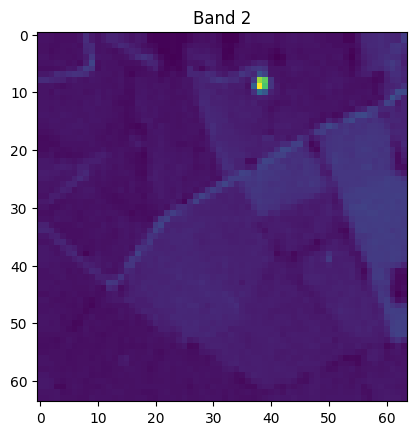

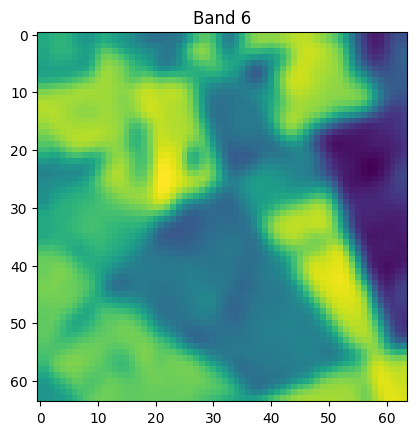

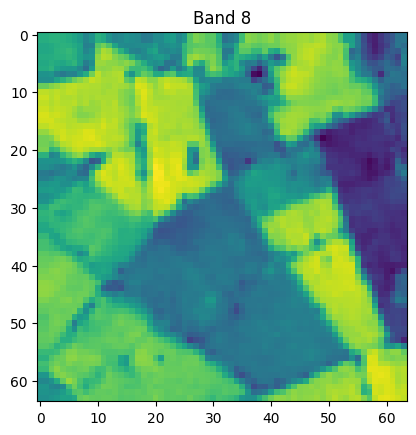

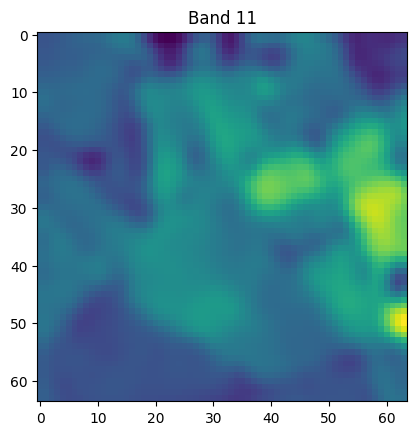

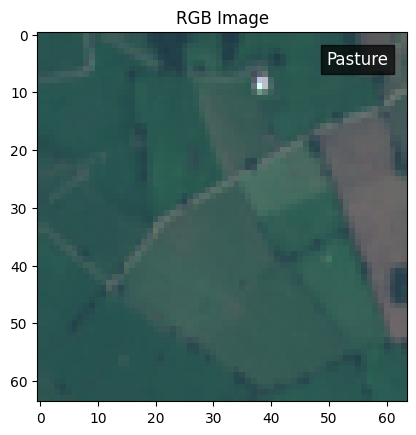

In [ ]:
import rasterio
import glob
import os
import matplotlib.pyplot as plt

# Define the path to the directory containing the data
datapath = "/content/EuroSAT/ds/images/remote_sensing/otherDatasets/sentinel_2/tif"

# Find all TIFF files in the directory and subdirectories
path_to_preview = glob.glob(os.path.join(datapath,"**","*.tif"),recursive=True)

# Read in the specified bands from the first TIFF file
with rasterio.open(path_to_preview[8000],"r") as src:
    # Note that band numbering in rasterio starts at 1, not 0
    band_nums = [2, 6, 8, 11]
    tempdata = src.read(band_nums)

# Plot each band separately and save as a PDF file
for i, band in enumerate(tempdata, start=1):
    # Get the band number from the source file
    with rasterio.open(path_to_preview[8000],"r") as src:
        band_num = src.indexes[band_nums[i-1]-1]

    # Plot the band and set the title to the band number
    plt.imshow(band)
    plt.title("Band {}".format(band_num))

    # Save the plot as a PDF file with the band number in the filename
    plt.savefig("band{}.pdf".format(band_num))

    # Show the plot in the notebook
    plt.show()

# Display and save the RGB image
with rasterio.open(path_to_preview[8000],"r") as src:
    # Read in the red, green, and blue bands
    rgb = src.read([4,3,2])

    # Normalize the bands to values between 0 and 1
    rgb = rgb / rgb.max()

    # Display the RGB image
    fig, ax = plt.subplots()
    im = ax.imshow(rgb.transpose(1,2,0))
    plt.title("RGB Image")

    # Get the class name from the file path and add it as a legend on the top right corner
    class_name = os.path.basename(os.path.dirname(path_to_preview[8000]))
    ax.text(0.95, 0.95, class_name, transform=ax.transAxes, ha='right', va='top', color='white', fontsize=12, bbox=dict(facecolor='black', alpha=0.7, pad=4))

    # Save the RGB image as a PDF file
    plt.savefig("rgb.pdf")

    # Show the plot in the notebook
    plt.show()


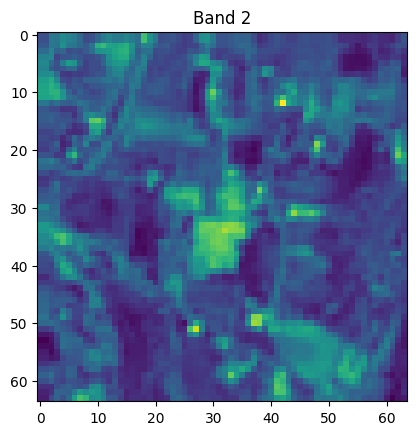

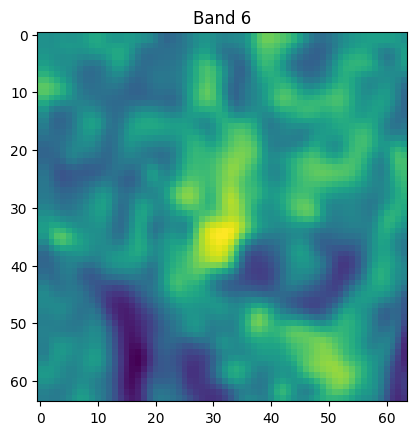

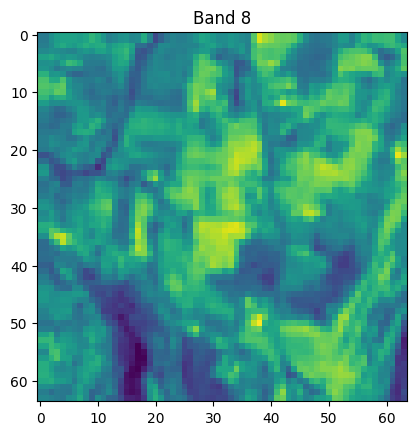

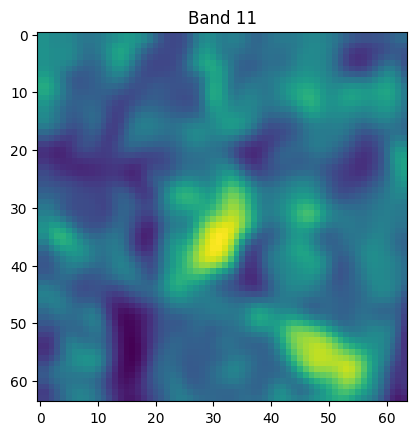

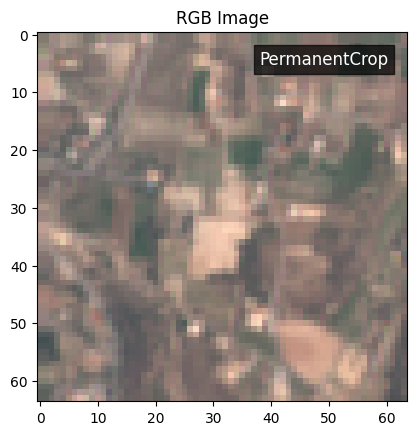

In [ ]:
import rasterio
import glob
import os
import matplotlib.pyplot as plt

# Define the path to the directory containing the data
datapath = "/content/EuroSAT/ds/images/remote_sensing/otherDatasets/sentinel_2/tif"

# Find all TIFF files in the directory and subdirectories
path_to_preview = glob.glob(os.path.join(datapath,"**","*.tif"),recursive=True)

# Read in the specified bands from the first TIFF file
with rasterio.open(path_to_preview[0],"r") as src:
    # Note that band numbering in rasterio starts at 1, not 0
    band_nums = [2, 6, 8, 11]
    tempdata = src.read(band_nums)

# Plot each band separately and save as a PDF file
for i, band in enumerate(tempdata, start=1):
    # Get the band number from the source file
    with rasterio.open(path_to_preview[0],"r") as src:
        band_num = src.indexes[band_nums[i-1]-1]

    # Plot the band and set the title to the band number
    plt.imshow(band)
    plt.title("Band {}".format(band_num))

    # Save the plot as a PDF file with the band number in the filename
    plt.savefig("band{}.pdf".format(band_num))

    # Show the plot in the notebook
    plt.show()

# Display and save the RGB image
with rasterio.open(path_to_preview[0],"r") as src:
    # Read in the red, green, and blue bands
    rgb = src.read([4,3,2])

    # Normalize the bands to values between 0 and 1
    rgb = rgb / rgb.max()

    # Display the RGB image
    fig, ax = plt.subplots()
    im = ax.imshow(rgb.transpose(1,2,0))
    plt.title("RGB Image")

    # Get the class name from the file path and add it as a legend on the top right corner
    class_name = os.path.basename(os.path.dirname(path_to_preview[0]))
    ax.text(0.95, 0.95, class_name, transform=ax.transAxes, ha='right', va='top', color='white', fontsize=12, bbox=dict(facecolor='black', alpha=0.7, pad=4))

    # Save the RGB image as a PDF file
    plt.savefig("rgb.pdf")

    # Show the plot in the notebook
    plt.show()


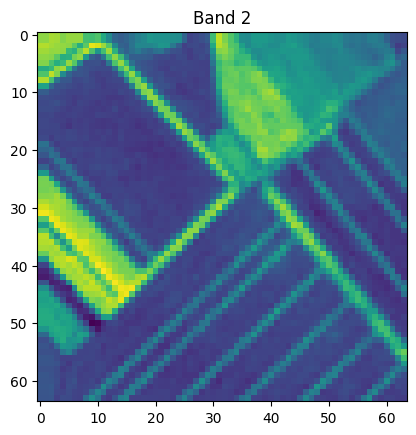

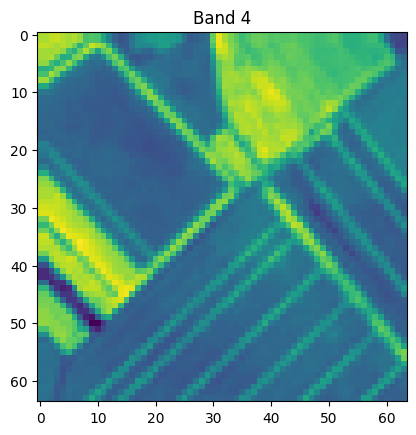

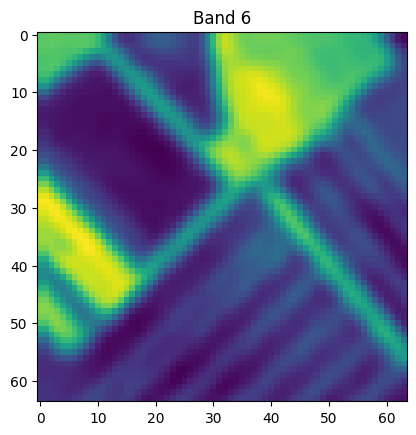

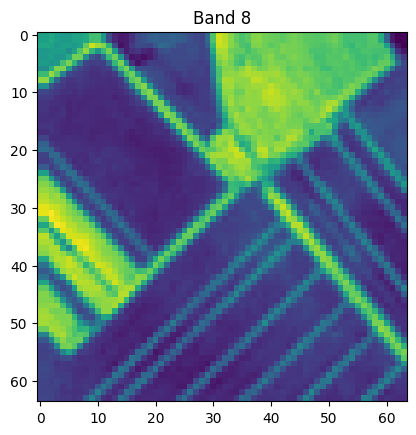

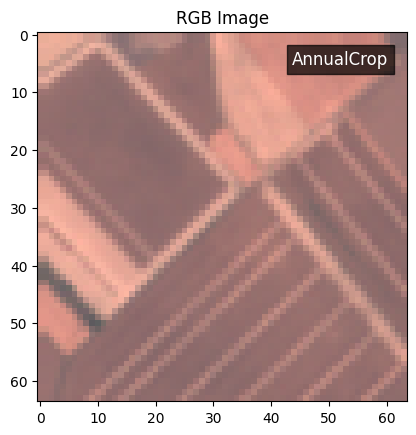

In [ ]:
import rasterio
import glob
import os
import matplotlib.pyplot as plt

# Define the path to the directory containing the data
datapath = "/content/EuroSAT/ds/images/remote_sensing/otherDatasets/sentinel_2/tif"

# Find all TIFF files in the directory and subdirectories
path_to_preview = glob.glob(os.path.join(datapath,"**","*.tif"),recursive=True)

# Read in the specified bands from the first TIFF file
with rasterio.open(path_to_preview[15000],"r") as src:
    # Note that band numbering in rasterio starts at 1, not 0
    band_nums = [2, 4, 6, 8]
    tempdata = src.read(band_nums)

# Plot each band separately and save as a PDF file
for i, band in enumerate(tempdata, start=1):
    # Get the band number from the source file
    with rasterio.open(path_to_preview[15000],"r") as src:
        band_num = src.indexes[band_nums[i-1]-1]

    # Plot the band and set the title to the band number
    plt.imshow(band)
    plt.title("Band {}".format(band_num))

    # Save the plot as a PDF file with the band number in the filename
    plt.savefig("band{}.pdf".format(band_num))

    # Show the plot in the notebook
    plt.show()

# Display and save the RGB image
with rasterio.open(path_to_preview[15000],"r") as src:
    # Read in the red, green, and blue bands
    rgb = src.read([4,3,2])

    # Normalize the bands to values between 0 and 1
    rgb = rgb / rgb.max()

    # Display the RGB image
    fig, ax = plt.subplots()
    im = ax.imshow(rgb.transpose(1,2,0))
    plt.title("RGB Image")

    # Get the class name from the file path and add it as a legend on the top right corner
    class_name = os.path.basename(os.path.dirname(path_to_preview[15000]))
    ax.text(0.95, 0.95, class_name, transform=ax.transAxes, ha='right', va='top', color='white', fontsize=12, bbox=dict(facecolor='black', alpha=0.7, pad=4))

    # Save the RGB image as a PDF file
    plt.savefig("rgb.pdf")

    # Show the plot in the notebook
    plt.show()


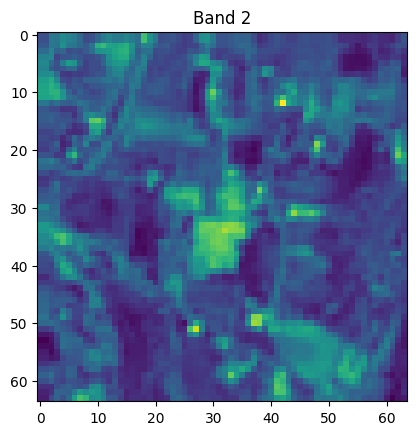

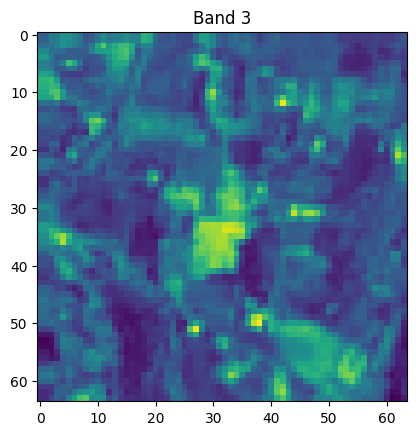

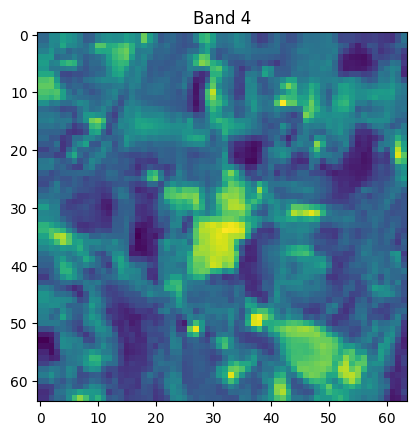

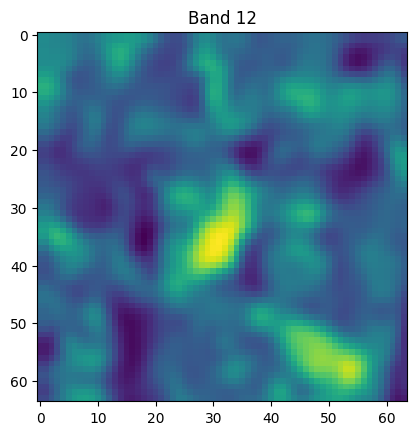

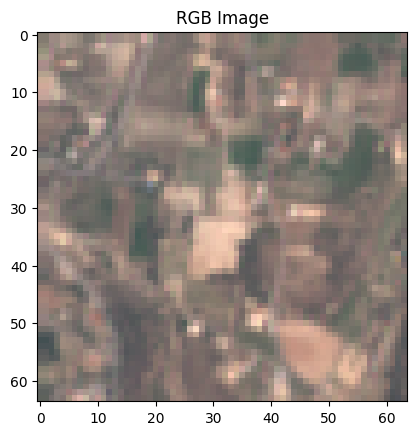

In [ ]:
import rasterio
import glob
import os
import matplotlib.pyplot as plt

# Define the path to the directory containing the data
datapath = "/content/EuroSAT/ds/images/remote_sensing/otherDatasets/sentinel_2/tif"

# Find all TIFF files in the directory and subdirectories
path_to_preview = glob.glob(os.path.join(datapath,"**","*.tif"),recursive=True)

# Read in the specified bands from the first TIFF file
with rasterio.open(path_to_preview[0],"r") as src:
    # Note that band numbering in rasterio starts at 1, not 0
    band_nums = [2, 3, 4, 12]
    tempdata = src.read(band_nums)

# Plot each band separately and save as a PDF file
for i, band in enumerate(tempdata, start=1):
    # Get the band number from the source file
    with rasterio.open(path_to_preview[0],"r") as src:
        band_num = src.indexes[band_nums[i-1]-1]

    # Plot the band and set the title to the band number
    plt.imshow(band)
    plt.title("Band {}".format(band_num))

    # Save the plot as a PDF file with the band number in the filename
    plt.savefig("band{}.pdf".format(band_num))

    # Show the plot in the notebook
    plt.show()

# Display and save the RGB image
with rasterio.open(path_to_preview[0],"r") as src:
    # Read in the red, green, and blue bands
    rgb = src.read([4,3,2])

    # Normalize the bands to values between 0 and 1
    rgb = rgb / rgb.max()

    # Display the RGB image
    plt.imshow(rgb.transpose(1,2,0))
    plt.title("RGB Image")

    # Save the RGB image as a PDF file
    plt.savefig("rgb.pdf")

    # Show the plot in the notebook
    plt.show()


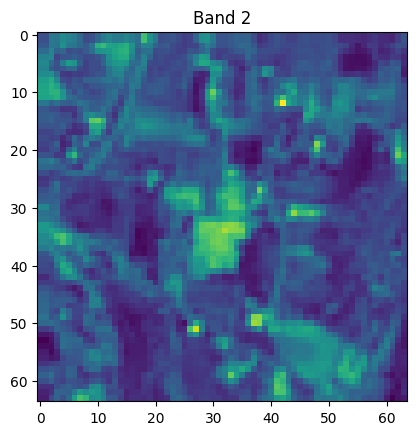

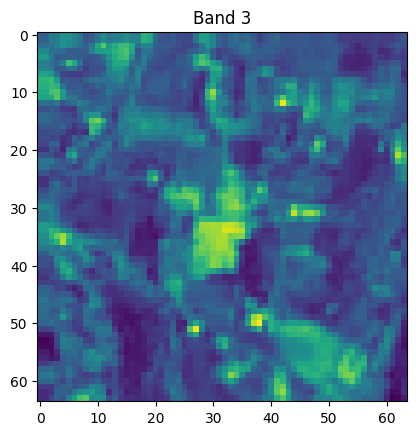

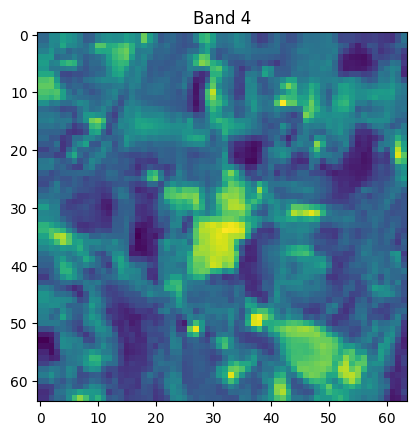

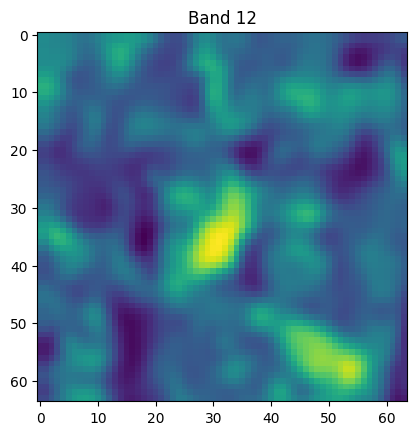

In [ ]:
import rasterio
import glob
import os
import matplotlib.pyplot as plt

# Define the path to the directory containing the data
datapath = "/content/EuroSAT/ds/images/remote_sensing/otherDatasets/sentinel_2/tif"

# Find all TIFF files in the directory and subdirectories
path_to_preview = glob.glob(os.path.join(datapath,"**","*.tif"),recursive=True)

# Read in the specified bands from the first TIFF file
with rasterio.open(path_to_preview[0],"r") as src:
    # Note that band numbering in rasterio starts at 1, not 0
    band_nums = [2, 3, 4, 12]
    tempdata = src.read(band_nums)

# Plot each band separately and save as a PDF file
for i, band in enumerate(tempdata, start=1):
    # Get the band number from the source file
    with rasterio.open(path_to_preview[0],"r") as src:
        band_num = src.indexes[band_nums[i-1]-1]

    # Plot the band and set the title to the band number
    plt.imshow(band)
    plt.title("Band {}".format(band_num))

    # Save the plot as a PDF file with the band number in the filename
    plt.savefig("band{}.pdf".format(band_num))

    # Show the plot in the notebook
    plt.show()


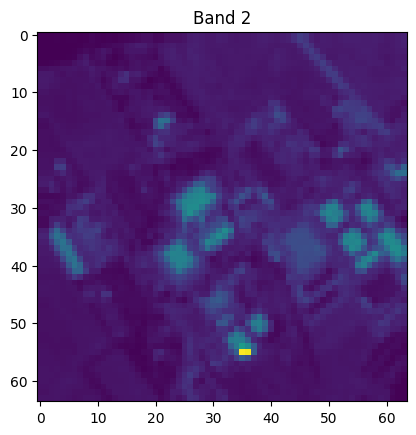

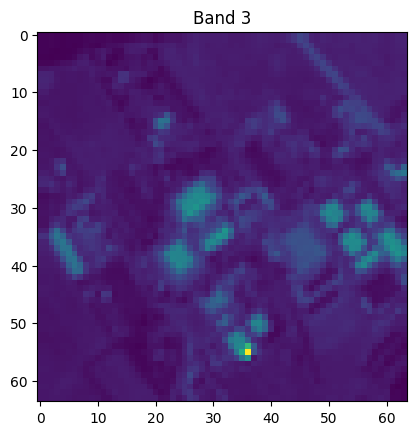

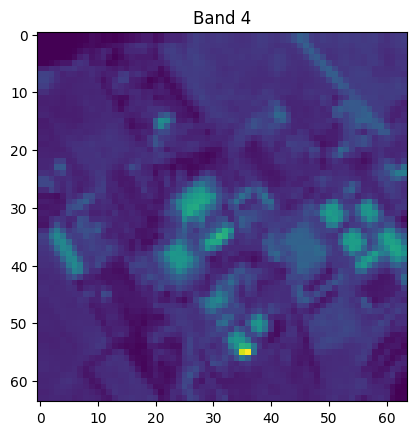

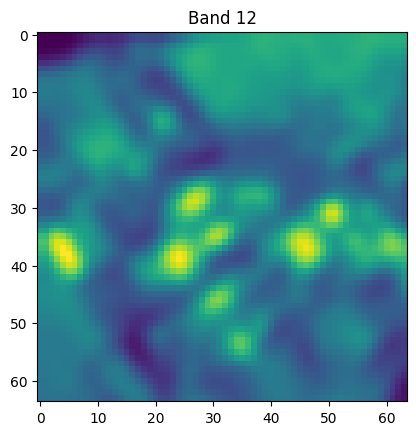

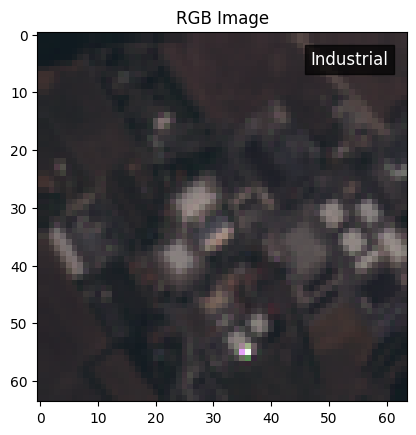

In [ ]:
import rasterio
import glob
import os
import matplotlib.pyplot as plt

# Define the path to the directory containing the data
datapath = "/content/EuroSAT/ds/images/remote_sensing/otherDatasets/sentinel_2/tif"

# Find all TIFF files in the directory and subdirectories
path_to_preview = glob.glob(os.path.join(datapath,"**","*.tif"),recursive=True)

# Read in the specified bands from the first TIFF file
with rasterio.open(path_to_preview[4000],"r") as src:
    # Note that band numbering in rasterio starts at 1, not 0
    band_nums = [2, 3, 4, 12]
    tempdata = src.read(band_nums)

# Plot each band separately and save as a PDF file
for i, band in enumerate(tempdata, start=1):
    # Get the band number from the source file
    with rasterio.open(path_to_preview[4000],"r") as src:
        band_num = src.indexes[band_nums[i-1]-1]

    # Plot the band and set the title to the band number
    plt.imshow(band)
    plt.title("Band {}".format(band_num))

    # Save the plot as a PDF file with the band number in the filename
    plt.savefig("band{}.pdf".format(band_num))

    # Show the plot in the notebook
    plt.show()

# Display and save the RGB image
with rasterio.open(path_to_preview[4000],"r") as src:
    # Read in the red, green, and blue bands
    rgb = src.read([4,3,2])

    # Normalize the bands to values between 0 and 1
    rgb = rgb / rgb.max()

    # Display the RGB image
    fig, ax = plt.subplots()
    im = ax.imshow(rgb.transpose(1,2,0))
    plt.title("RGB Image")

    # Get the class name from the file path and add it as a legend on the top right corner
    class_name = os.path.basename(os.path.dirname(path_to_preview[4000]))
    ax.text(0.95, 0.95, class_name, transform=ax.transAxes, ha='right', va='top', color='white', fontsize=12, bbox=dict(facecolor='black', alpha=0.7, pad=4))

    # Save the RGB image as a PDF file
    plt.savefig("rgb.pdf")

    # Show the plot in the notebook
    plt.show()


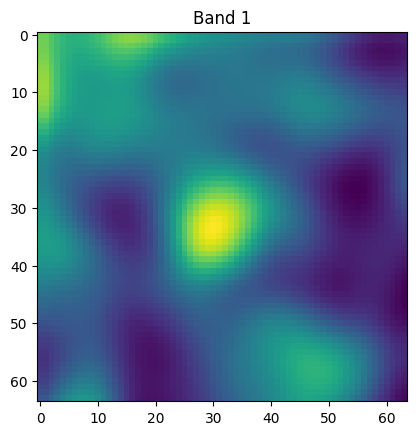

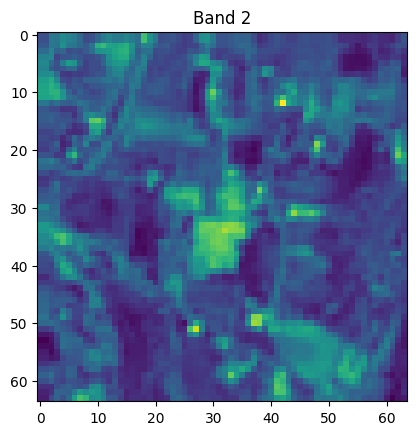

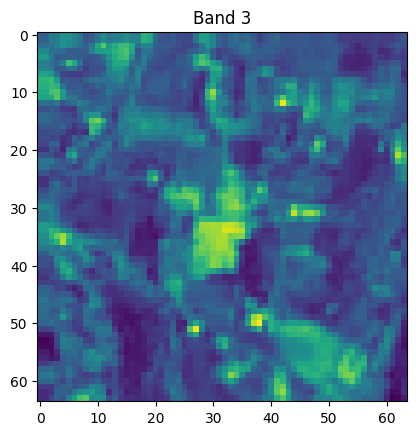

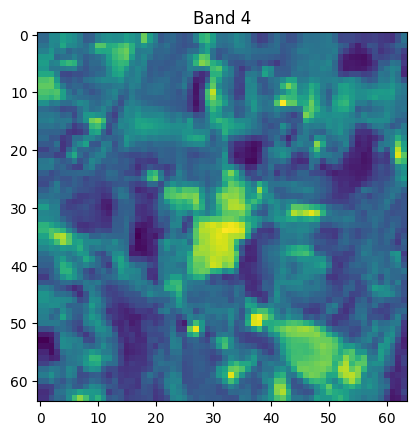

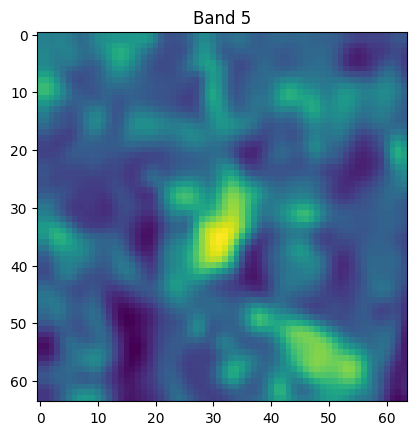

...

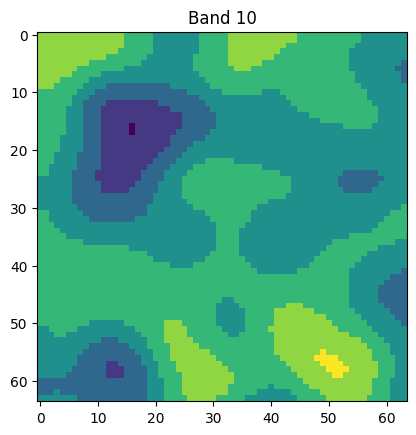

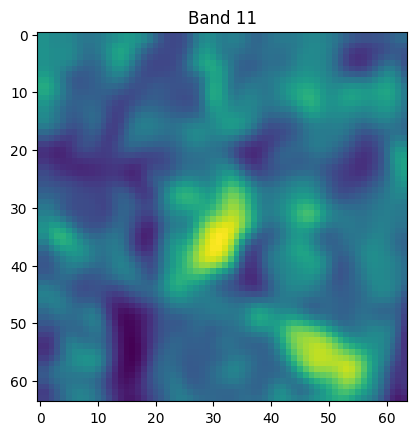

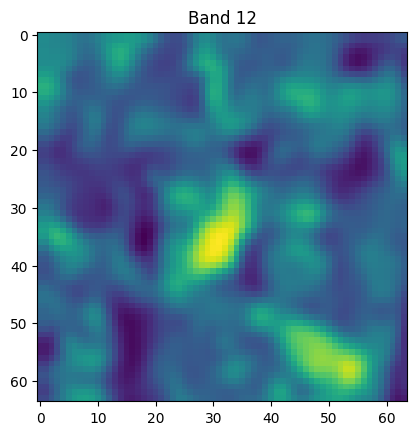

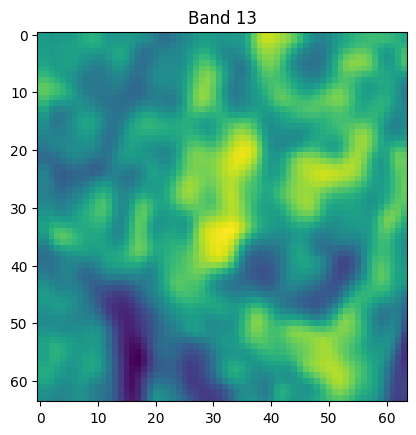

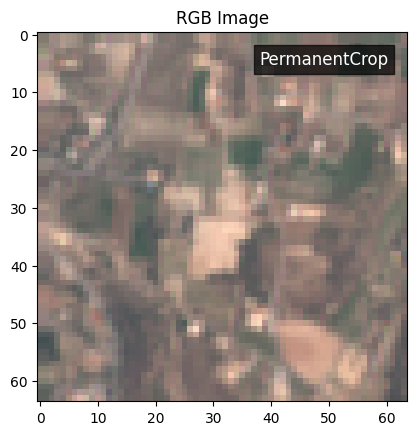

In [ ]:
import rasterio
import glob
import os
import matplotlib.pyplot as plt

# Define the path to the directory containing the data
datapath = "/content/EuroSAT/ds/images/remote_sensing/otherDatasets/sentinel_2/tif"

# Find all TIFF files in the directory and subdirectories
path_to_preview = glob.glob(os.path.join(datapath,"**","*.tif"),recursive=True)

# Read in the specified bands from the first TIFF file
with rasterio.open(path_to_preview[0],"r") as src:
    # Note that band numbering in rasterio starts at 1, not 0
    band_nums = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]
    tempdata = src.read(band_nums)

# Plot each band separately and save as a PDF file
for i, band in enumerate(tempdata, start=1):
    # Get the band number from the source file
    with rasterio.open(path_to_preview[0],"r") as src:
        band_num = src.indexes[band_nums[i-1]-1]

    # Plot the band and set the title to the band number
    plt.imshow(band)
    plt.title("Band {}".format(band_num))

    # Save the plot as a PDF file with the band number in the filename
    plt.savefig("band{}.pdf".format(band_num))

    # Show the plot in the notebook
    plt.show()

# Display and save the RGB image
with rasterio.open(path_to_preview[0],"r") as src:
    # Read in the red, green, and blue bands
    rgb = src.read([4,3,2])

    # Normalize the bands to values between 0 and 1
    rgb = rgb / rgb.max()

    # Display the RGB image
    fig, ax = plt.subplots()
    im = ax.imshow(rgb.transpose(1,2,0))
    plt.title("RGB Image")

    # Get the class name from the file path and add it as a legend on the top right corner
    class_name = os.path.basename(os.path.dirname(path_to_preview[0]))
    ax.text(0.95, 0.95, class_name, transform=ax.transAxes, ha='right', va='top', color='white', fontsize=12, bbox=dict(facecolor='black', alpha=0.7, pad=4))

    # Save the RGB image as a PDF file
    plt.savefig("rgb.pdf")

    # Show the plot in the notebook
    plt.show()


## Define Classess

In [ ]:
import os

# Get list of class names in alphabetical order
classes = (os.listdir(datapath))

# Print list of classes
print(classes)

# Check that the list of classes is not empty
assert len(classes) > 0

# Check that each class name is valid (for example, does not contain whitespace)
for class_name in classes:
    assert class_name.strip() == class_name

['PermanentCrop', 'Industrial', 'River', 'Pasture', 'HerbaceousVegetation', 'AnnualCrop', 'Residential', 'SeaLake', 'Forest', 'Highway']


In [ ]:
classes = os.listdir(datapath)
print(classes)


['PermanentCrop', 'Industrial', 'River', 'Pasture', 'HerbaceousVegetation', 'AnnualCrop', 'Residential', 'SeaLake', 'Forest', 'Highway']


In [ ]:
RS = np.random.RandomState(seed=69422)

# make sure you set the path correctly
classes = sorted(os.listdir(datapath))
assert sorted(classes) == sorted(['HerbaceousVegetation', 'Industrial', 'Pasture', 'River', 'AnnualCrop', 'Highway', 'Residential', 'Forest', 'SeaLake', 'PermanentCrop'])

In [ ]:
classes

['AnnualCrop',
 'Forest',
 'HerbaceousVegetation',
 'Highway',
 'Industrial',
 'Pasture',
 'PermanentCrop',
 'Residential',
 'River',
 'SeaLake']

# Model and Train

## Define Model

### Get the model

In [ ]:
import torch
import torch.nn as nn
from torchsummary import summary

# Load the pre-trained VGG-16 model
model = models.vgg16(pretrained=True)

# Move the model to the GPU
model.cuda()

# Print the model summary
summary(model, input_size=(3, 64, 64))

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:03<00:00, 163MB/s]


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 64, 64]           1,792
              ReLU-2           [-1, 64, 64, 64]               0
            Conv2d-3           [-1, 64, 64, 64]          36,928
              ReLU-4           [-1, 64, 64, 64]               0
         MaxPool2d-5           [-1, 64, 32, 32]               0
            Conv2d-6          [-1, 128, 32, 32]          73,856
              ReLU-7          [-1, 128, 32, 32]               0
            Conv2d-8          [-1, 128, 32, 32]         147,584
              ReLU-9          [-1, 128, 32, 32]               0
        MaxPool2d-10          [-1, 128, 16, 16]               0
           Conv2d-11          [-1, 256, 16, 16]         295,168
             ReLU-12          [-1, 256, 16, 16]               0
           Conv2d-13          [-1, 256, 16, 16]         590,080
             ReLU-14          [-1, 256,

### Adapt the model to our Dataset
Change first and last layer to match a four channel input and ten class classification problem

In [ ]:
import torch
import torch.nn as nn
from torchsummary import summary

# Load the pre-trained VGG-16 model
model = models.vgg16(pretrained=True)

# Modify the first convolutional layer to accept 4 channels instead of 3
model.features[0] = nn.Conv2d(4, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))

# Modify the last fully connected layer to output 10 classes instead of 1000
model.classifier[-1] = nn.Linear(in_features=4096, out_features=10, bias=True)

# Move the model to the GPU
model.cuda()

# Print the model summary
summary(model, input_size=(4, 64, 64))


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 64, 64]           2,368
              ReLU-2           [-1, 64, 64, 64]               0
            Conv2d-3           [-1, 64, 64, 64]          36,928
              ReLU-4           [-1, 64, 64, 64]               0
         MaxPool2d-5           [-1, 64, 32, 32]               0
            Conv2d-6          [-1, 128, 32, 32]          73,856
              ReLU-7          [-1, 128, 32, 32]               0
            Conv2d-8          [-1, 128, 32, 32]         147,584
              ReLU-9          [-1, 128, 32, 32]               0
        MaxPool2d-10          [-1, 128, 16, 16]               0
           Conv2d-11          [-1, 256, 16, 16]         295,168
             ReLU-12          [-1, 256, 16, 16]               0
           Conv2d-13          [-1, 256, 16, 16]         590,080
             ReLU-14          [-1, 256,

## Functions for gathering all the images and their corresponding class labels are defined.

To create a balanced dataset, we limit the number of images per class to 2k. Alternatively, this issue could be addressed in the loss function.

In [ ]:
def get_list_of_samples(datapath):

    sample_toupels = [] # a list to hold sample-tuples

    # Loop over each class in the dataset
    for ijk, _class in enumerate(classes):

        # Get a list of all sample files for the current class
        all_samples_in_class = glob.glob(os.path.join(datapath,_class,"*.tif"))

        # Limit the number of samples to 2000 per class to create a balanced dataset
        all_samples_in_class = all_samples_in_class[:2000]

        # Create a dictionary for each sample that includes the file path and class label
        for sample in all_samples_in_class:
            sample_toupels.append({"X":sample,"Y":ijk})

    # Return the list of dictionaries containing the image file paths and class labels
    return sample_toupels


# Train Images 15200
# Val Images 2400
# Test Images 2400


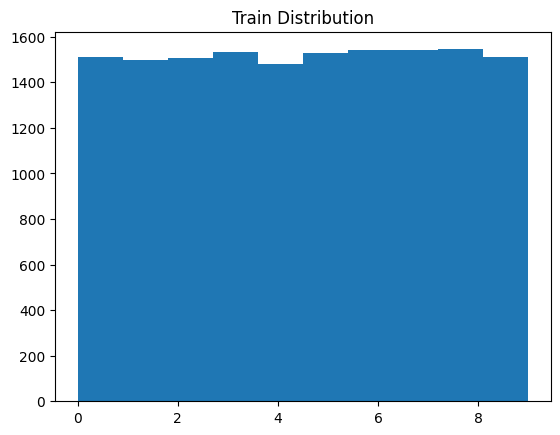

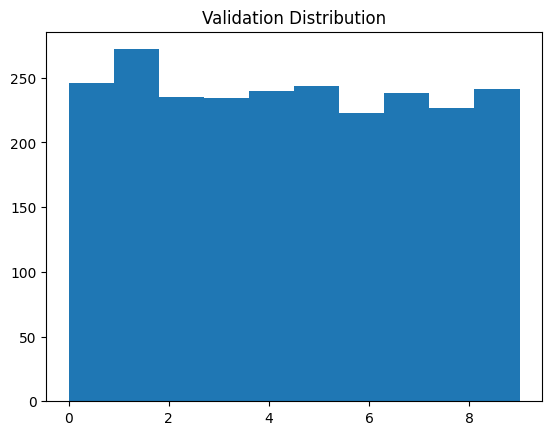

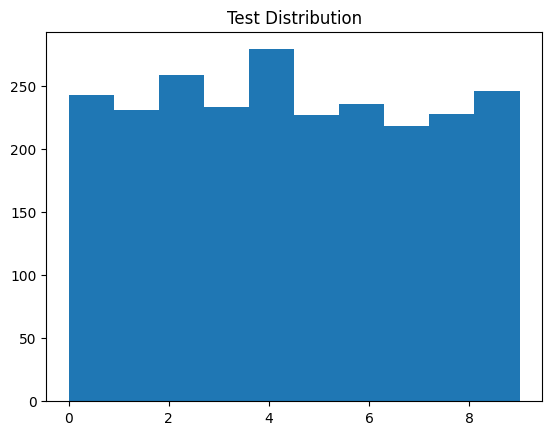

In [ ]:
import random as RS
import matplotlib.pyplot as plt

# Define a function to get a list of samples from a given datapath
# def get_list_of_samples(datapath):
#     # Code to get a list of samples from the datapath
#     pass

# Get a list of all samples from the datapath
all_samples = get_list_of_samples(datapath)

# Shuffle the samples randomly
RS.shuffle(all_samples)

# Define the ratios for train, validation, and test sets
train_ratio = 0.76
val_ratio = 0.12
test_ratio = 0.12

# Calculate the number of samples for each set based on the ratios
num_samples = len(all_samples)
num_train = int(num_samples * train_ratio)
num_val = int(num_samples * val_ratio)
num_test = num_samples - num_train - num_val

# Split the shuffled samples into train, validation, and test sets
train_locations = all_samples[:num_train]
val_locations = all_samples[num_train:num_train+num_val]
test_locations = all_samples[num_train+num_val:]

# Print the number of samples in each set
print("# Train Images", len(train_locations))
print("# Val Images", len(val_locations))
print("# Test Images", len(test_locations))

# Plot the distribution of the Y values for the train set and save as a PDF
temp_hist = []
for d in train_locations:
    temp_hist.append(d["Y"])
plt.hist(temp_hist)
plt.title("Train Distribution")
plt.savefig("traindistribution.pdf")
plt.show()

# Plot the distribution of the Y values for the validation set and save as a PDF
temp_hist = []
for d in val_locations:
    temp_hist.append(d["Y"])
plt.hist(temp_hist)
plt.title("Validation Distribution")
plt.savefig("validationdistribution.pdf")
plt.show()

# Plot the distribution of the Y values for the test set and save as a PDF
temp_hist = []
for d in test_locations:
    temp_hist.append(d["Y"])
plt.hist(temp_hist)
plt.title("Test Distribution")
plt.savefig("testdistribution.pdf")
plt.show()


## Dataloader

In [ ]:
import rasterio
import numpy as np
import torch
from torch.utils import data
from torch.utils.data import DataLoader
import warnings
warnings.filterwarnings("ignore")

# Define a dataset class for the Super Resolution (SR) model
class class_dataset(data.Dataset):

    # Constructor to initialize the samplelist for the dataset
    def __init__(self, samplelist):
        self.samplelist = samplelist

    # Method to get the data and label tensors for a given index
    def __getitem__(self, i):

        # Open the image file using rasterio
        with rasterio.open(self.samplelist[i]["X"], "r") as src:

            # Read the data from bands 2, 3, 4, and 8 as a float32 array
            data = src.read((2,3,4,8)).astype("float32")

            # Normalize the data to [0,1] range
            data = data / 10000

            # Clip the data to [0,1] range
            data = np.clip(data, 0, 1)

        # Return the data tensor and the label tensor as a tuple
        return torch.Tensor(data), torch.Tensor([self.samplelist[i]["Y"]]).long()

    # Method to get the length of the dataset
    def __len__(self):
        return len(self.samplelist)

# Create datasets and dataloaders for train, validation, and test sets
train_set = class_dataset(train_locations)
val_set = class_dataset(val_locations)
test_set = class_dataset(test_locations)

# Setup the dataloader with the given number of worker threads, batch size, and shuffle option
training_data_loader = DataLoader(dataset=train_set, num_workers=threads, batch_size=batch_size, shuffle=True, drop_last=True)
val_data_loader = DataLoader(dataset=val_set, num_workers=threads, batch_size=batch_size, shuffle=True, drop_last=True)
test_data_loader = DataLoader(dataset=test_set, num_workers=threads, batch_size=batch_size, shuffle=True, drop_last=True)

### Show one batch

torch.Size([16, 4, 64, 64]) torch.Size([16, 1])


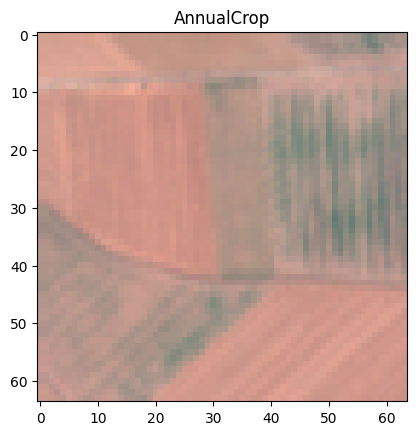

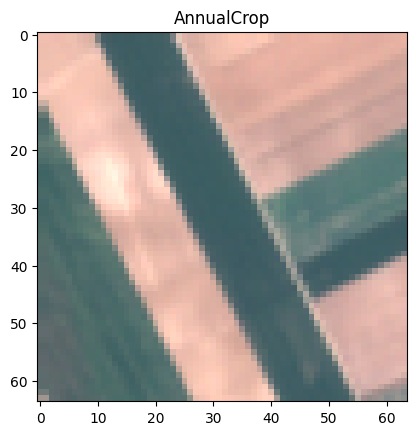

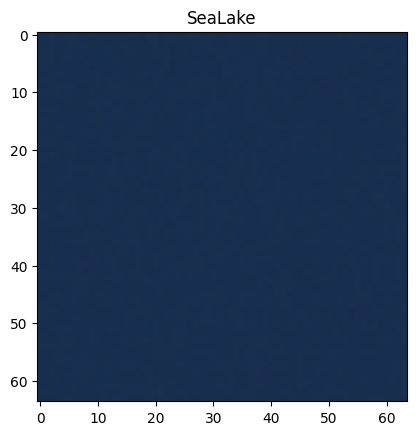

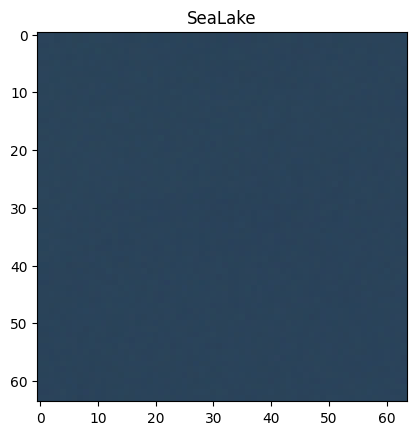

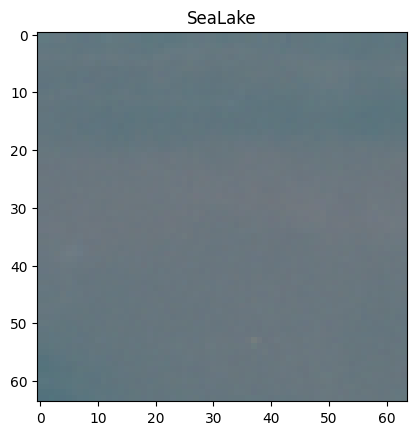

...

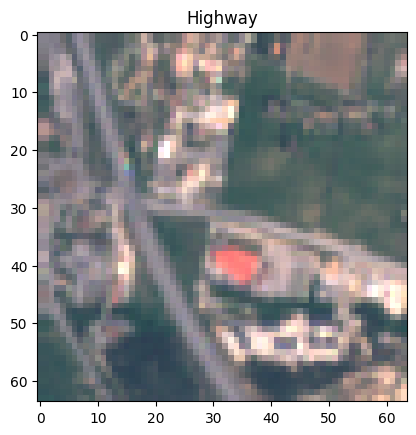

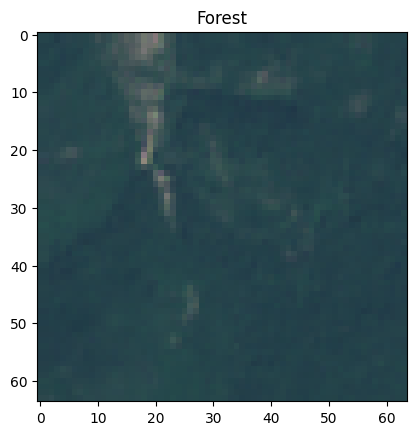

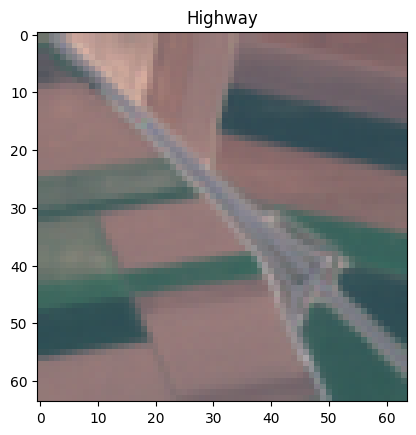

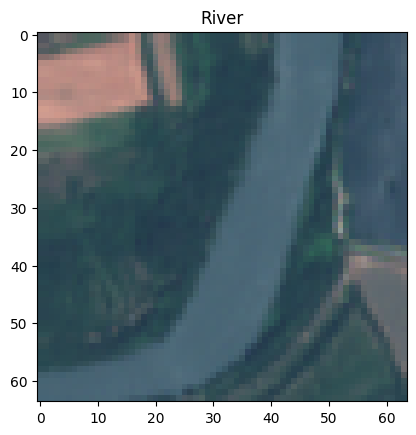

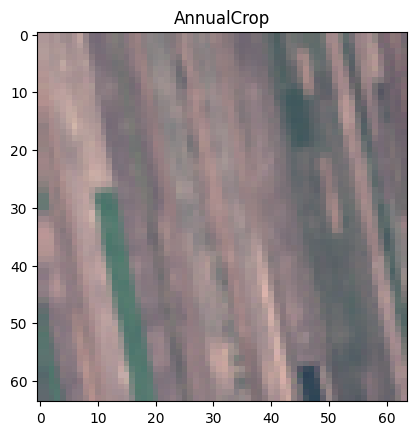

In [ ]:
# Loop over the first batch of images and their corresponding labels
for img, label in val_data_loader:
    # Only process the first batch
    break

# Print the shape of the first image and its label
print(img.shape,label.shape)

# Loop over each image in the batch
for batchindex in range(batch_size):

    # Extract the B, G, R color channels from the image
    B,G,R = img[batchindex,:3,:,:]
    # Stack the channels to form a colored image
    plot_img = np.stack([R,G,B],axis=-1)
    # Increase the brightness of the image by a factor of 4
    plot_img = np.clip(plot_img*4,0,1)

    # Display the image along with its corresponding label
    plt.imshow(plot_img)
    plt.title(classes[label[batchindex].numpy()[0]])
    plt.show()

torch.Size([16, 4, 64, 64]) torch.Size([16, 1])


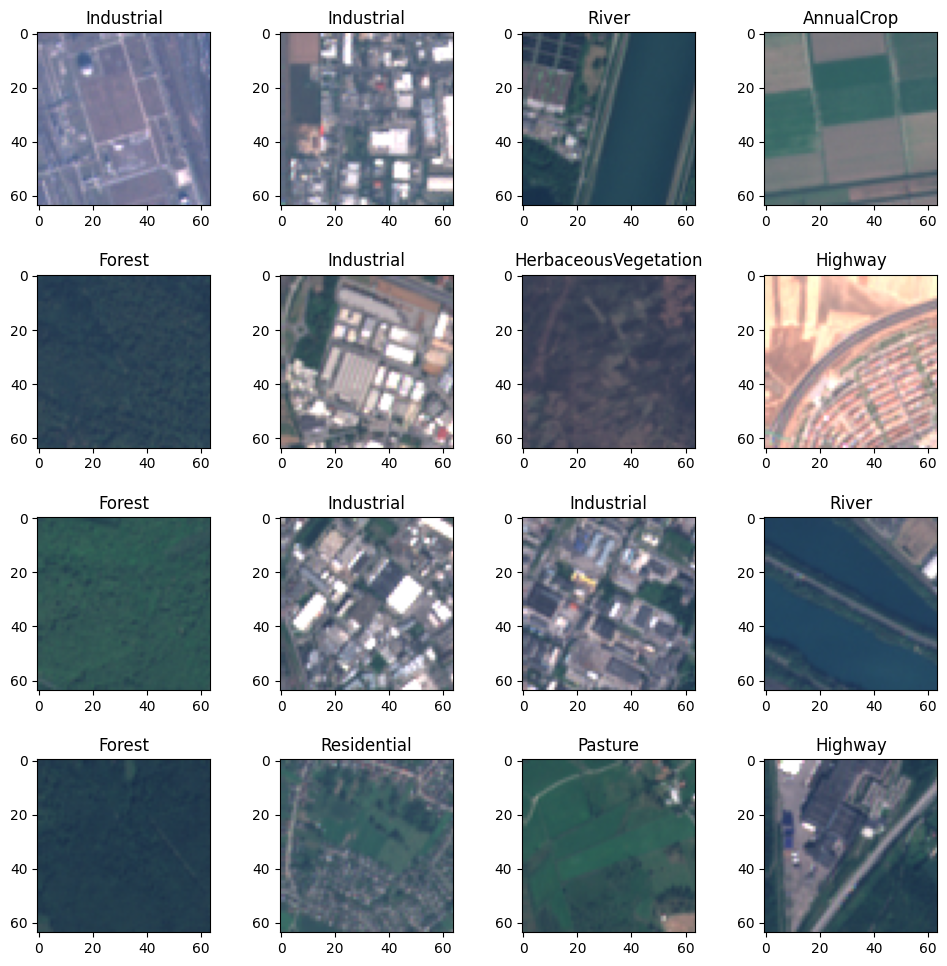

In [ ]:
# Loop over the first batch of images and their corresponding labels
for img, label in val_data_loader:
    # Only process the first batch
    break

# Print the shape of the first image and its label
print(img.shape,label.shape)

# Create a 4x4 grid for the images with margins of 0.2 on all sides
fig, axs = plt.subplots(4, 4, figsize=(10,10))
fig.subplots_adjust(hspace=0.4, wspace=0.4, top=0.95, bottom=0.05, left=0.05, right=0.95)

# Loop over each image in the batch
for batchindex in range(batch_size):

    # Extract the B, G, R color channels from the image
    B,G,R = img[batchindex,:3,:,:]
    # Stack the channels to form a colored image
    plot_img = np.stack([R,G,B],axis=-1)
    # Increase the brightness of the image by a factor of 4
    plot_img = np.clip(plot_img*4,0,1)

    # Display the image along with its corresponding label in the grid
    row = batchindex // 4
    col = batchindex % 4
    axs[row, col].imshow(plot_img)
    axs[row, col].set_title(classes[label[batchindex].numpy()[0]])

# Set the title of the plot
# fig.suptitle('First batch of validation images')
# Hide the x and y axis labels for all subplots
for ax in axs.flat:
    ax.set(xlabel='', ylabel='')
# Save the plot
plt.savefig('batchimages.pdf')
# Show the plot
plt.show()

torch.Size([16, 4, 64, 64]) torch.Size([16, 1])


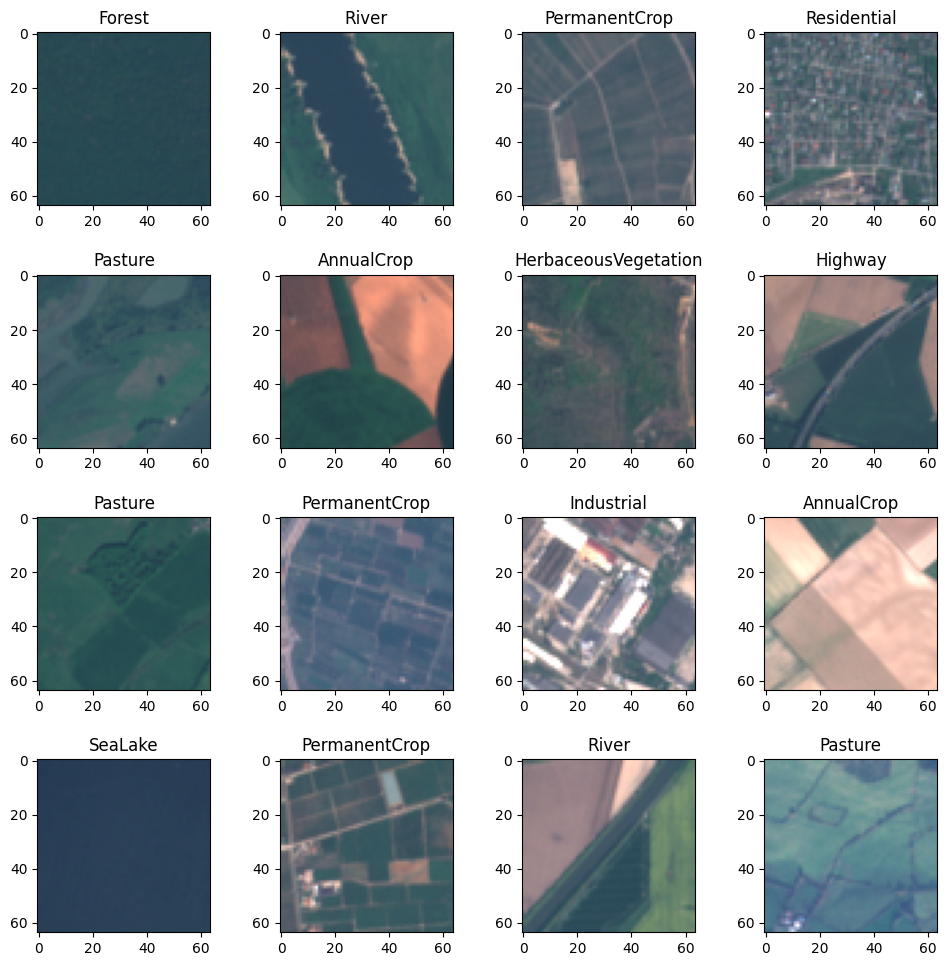

In [ ]:
# Loop over the first batch of images and their corresponding labels
for img, label in val_data_loader:
    # Only process the first batch
    break

# Print the shape of the first image and its label
print(img.shape,label.shape)

# Create a 4x4 grid for the images with margins of 0.2 on all sides
fig, axs = plt.subplots(4, 4, figsize=(10,10))
fig.subplots_adjust(hspace=0.4, wspace=0.4, top=0.95, bottom=0.05, left=0.05, right=0.95)

# Loop over each image in the batch
for batchindex in range(batch_size):

    # Extract the B, G, R color channels from the image
    B,G,R = img[batchindex,:3,:,:]
    # Stack the channels to form a colored image
    plot_img = np.stack([R,G,B],axis=-1)
    # Increase the brightness of the image by a factor of 4
    plot_img = np.clip(plot_img*4,0,1)

    # Display the image along with its corresponding label in the grid
    row = batchindex // 4
    col = batchindex % 4
    axs[row, col].imshow(plot_img)
    axs[row, col].set_title(classes[label[batchindex].numpy()[0]])

# Set the title of the plot
# fig.suptitle('First batch of validation images')
# Hide the x and y axis labels for all subplots
for ax in axs.flat:
    ax.set(xlabel='', ylabel='')
# Save the plot
plt.savefig('batchimages.pdf')
# Show the plot
plt.show()

# Training

## Setup Model and Trainings Parameters

In [ ]:
# Define model and training parameters
batch_size = 16  # Batch size for training
threads = 6  # Number of threads for data loading
learning_rate = 0.001  # Learning rate for the optimizer
momentum = 0.9  # Momentum factor for the optimizer

# Define loss function and optimizer
criterion = torch.nn.CrossEntropyLoss()  # Cross-entropy loss function
optimizer = optim.SGD(model.parameters(), lr=learning_rate, momentum=momentum)  # Stochastic Gradient Descent optimizer with specified learning rate and momentum

## Main Trainings Code

Epoch [1/18], Train Loss: 1.2134, Train Acc: 0.5655, Val Loss: 0.5532, Val Acc: 0.8063
Epoch [2/18], Train Loss: 0.4899, Train Acc: 0.8368, Val Loss: 0.3473, Val Acc: 0.8792
Epoch [3/18], Train Loss: 0.3258, Train Acc: 0.8925, Val Loss: 0.3229, Val Acc: 0.8975
Epoch [4/18], Train Loss: 0.2489, Train Acc: 0.9173, Val Loss: 0.2898, Val Acc: 0.9017
Epoch [5/18], Train Loss: 0.2023, Train Acc: 0.9317, Val Loss: 0.3112, Val Acc: 0.8942
Epoch [6/18], Train Loss: 0.1538, Train Acc: 0.9455, Val Loss: 0.1870, Val Acc: 0.9388
Epoch [7/18], Train Loss: 0.1243, Train Acc: 0.9597, Val Loss: 0.1939, Val Acc: 0.9363
Epoch [8/18], Train Loss: 0.1011, Train Acc: 0.9662, Val Loss: 0.2217, Val Acc: 0.9271
Epoch [9/18], Train Loss: 0.0876, Train Acc: 0.9718, Val Loss: 0.1686, Val Acc: 0.9454
Epoch [10/18], Train Loss: 0.0802, Train Acc: 0.9724, Val Loss: 0.2078, Val Acc: 0.9450
Epoch [11/18], Train Loss: 0.0627, Train Acc: 0.9790, Val Loss: 0.1896, Val Acc: 0.9471
Epoch [12/18], Train Loss: 0.0578, Train 

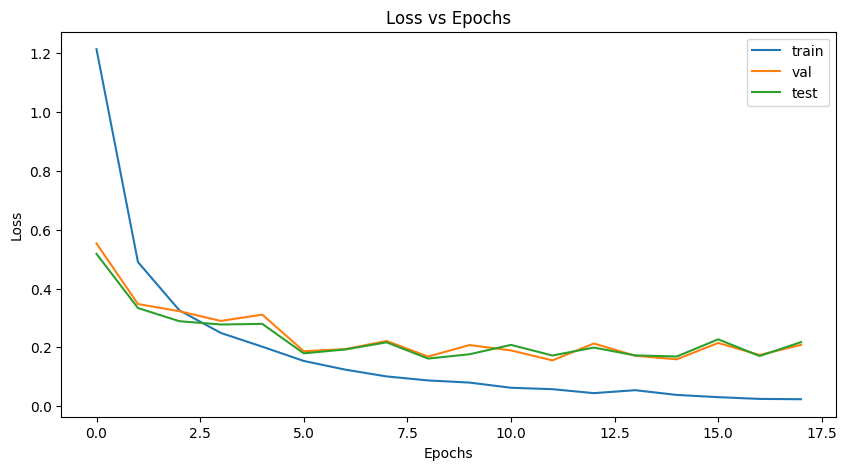

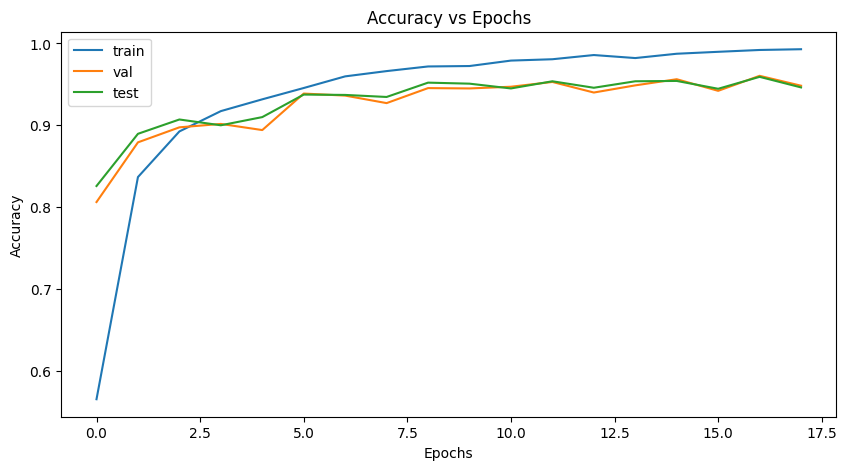

Test Accuracy: 0.9304
Test Error: 0.0696
Test Precision: 0.9307
Test Recall: 0.9304
Test F1-score: 0.9303


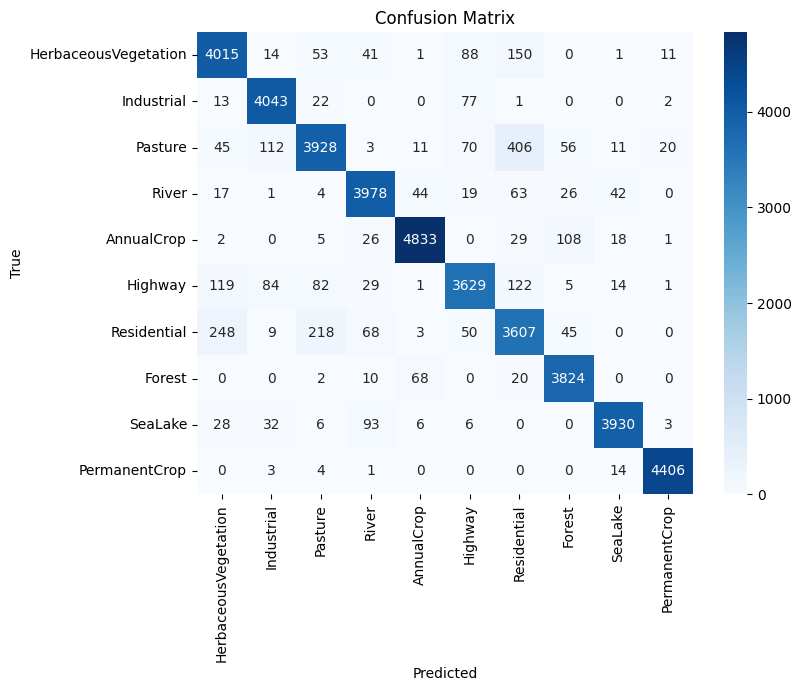

In [ ]:
# Create empty lists for storing loss and accuracy for train, val, and test
train_loss = []
train_acc = []
val_loss = []
val_acc = []
test_loss = []
test_acc = []

# Create a list to store predicted and true labels for test set
pred_labels = []
true_labels = []

num_epochs = 18

# Training loop
for epoch in range(num_epochs):
    # Train the model
    model.train()
    running_loss = 0.0
    running_corrects = 0
    total = 0
    for i, (inputs, labels) in enumerate(training_data_loader):
        inputs = inputs.cuda()
        labels = labels.squeeze().long().cuda()
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        running_corrects += torch.sum(preds == labels.data)
        total += labels.size(0)
    train_loss.append(running_loss / len(train_set))
    train_acc.append(running_corrects.double() / total)

    # Evaluate on the validation set
    model.eval()
    running_loss = 0.0
    running_corrects = 0
    total = 0
    with torch.no_grad():
        for i, (inputs, labels) in enumerate(val_data_loader):
            inputs = inputs.cuda()
            labels = labels.squeeze().long().cuda()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            running_corrects += torch.sum(preds == labels.data)
            total += labels.size(0)
    val_loss.append(running_loss / len(val_set))
    val_acc.append(running_corrects.double() / total)

    # Evaluate on the test set
    model.eval()
    running_loss = 0.0
    running_corrects = 0
    total = 0
    with torch.no_grad():
        for i, (inputs, labels) in enumerate(test_data_loader):
            inputs = inputs.cuda()
            labels = labels.squeeze().long().cuda()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            running_corrects += torch.sum(preds == labels.data)
            total += labels.size(0)
            pred_labels.extend(preds.cpu().numpy())
            true_labels.extend(labels.cpu().numpy())
    test_loss.append(running_loss / len(test_set))
    test_acc.append(running_corrects.double() / total)

    # Print epoch, loss, and accuracy for train and val sets
    print('Epoch [{}/{}], Train Loss: {:.4f}, Train Acc: {:.4f}, Val Loss: {:.4f}, Val Acc: {:.4f}'
          .format(epoch+1, num_epochs, train_loss[-1], train_acc[-1], val_loss[-1], val_acc[-1]))

# Plot the loss and accuracy curves for train, val, and test sets
plt.figure(figsize=(10, 5))
plt.plot(train_loss, label='train')
plt.plot(val_loss, label='val')
plt.plot(test_loss, label='test')
plt.title('Loss vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.savefig('loss.pdf')
plt.show()

train_acc = torch.tensor(train_acc)
val_acc = torch.tensor(val_acc)
test_acc = torch.tensor(test_acc)

# Plot the loss and accuracy curves for train, val, and test sets
plt.figure(figsize=(10, 5))
plt.plot(train_acc, label='train')
plt.plot(val_acc, label='val')
plt.plot(test_acc, label='test')
plt.title('Accuracy vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.savefig('Accuracy.pdf')
plt.show()

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

accuracy = accuracy_score(true_labels, pred_labels)
error = 1 - accuracy
precision = precision_score(true_labels, pred_labels, average='weighted')
recall = recall_score(true_labels, pred_labels, average='weighted')
f1score = f1_score(true_labels, pred_labels, average='weighted')

print('Test Accuracy: {:.4f}'.format(accuracy))
print('Test Error: {:.4f}'.format(error))
print('Test Precision: {:.4f}'.format(precision))
print('Test Recall: {:.4f}'.format(recall))
print('Test F1-score: {:.4f}'.format(f1score))

import seaborn as sns
confusion_matrix = np.zeros((10, 10))
for i in range(len(true_labels)):
  true_idx = true_labels[i]
  pred_idx = pred_labels[i]
  confusion_matrix[true_idx][pred_idx] += 1

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix, annot=True, cmap='Blues', fmt='g', xticklabels=['HerbaceousVegetation', 'Industrial', 'Pasture', 'River', 'AnnualCrop', 'Highway', 'Residential', 'Forest', 'SeaLake', 'PermanentCrop'], yticklabels=['HerbaceousVegetation', 'Industrial', 'Pasture', 'River', 'AnnualCrop', 'Highway', 'Residential', 'Forest', 'SeaLake', 'PermanentCrop'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.savefig('confusion_matrix.pdf')
plt.show()

# Save the trained model
torch.save(model.state_dict(), 'model.pth')


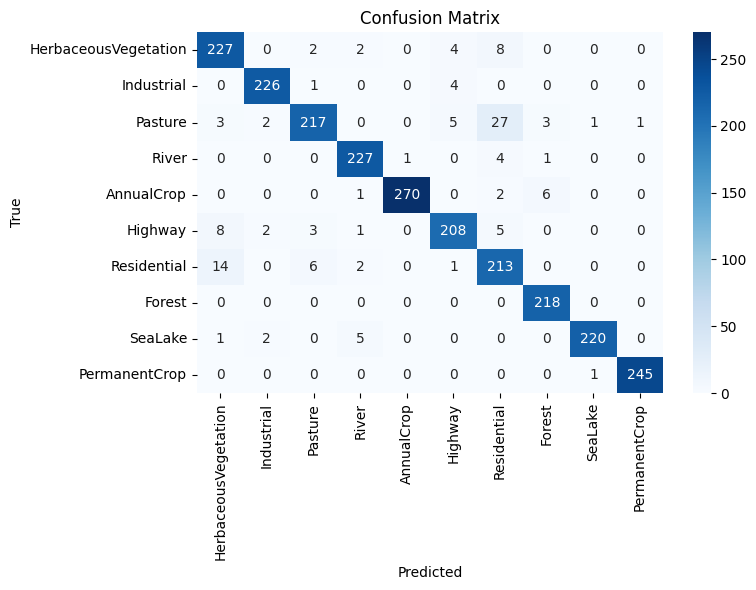

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Set the model to evaluation mode
model.eval()

# Create empty lists to store predicted and true labels
pred_labels = []
true_labels = []

# Loop through the test set and get predictions and true labels
with torch.no_grad():
    for i, (inputs, labels) in enumerate(test_data_loader):
        inputs = inputs.cuda()
        labels = labels.squeeze().long().cuda()
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        pred_labels.extend(preds.cpu().numpy())
        true_labels.extend(labels.cpu().numpy())

from matplotlib.backends.backend_pdf import PdfPages

# Compute the confusion matrix
confusion_matrix = confusion_matrix(true_labels, pred_labels)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix, annot=True, cmap='Blues', fmt='g', xticklabels=['HerbaceousVegetation', 'Industrial', 'Pasture', 'River', 'AnnualCrop', 'Highway', 'Residential', 'Forest', 'SeaLake', 'PermanentCrop'], yticklabels=['HerbaceousVegetation', 'Industrial', 'Pasture', 'River', 'AnnualCrop', 'Highway', 'Residential', 'Forest', 'SeaLake', 'PermanentCrop'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.tight_layout()

# Save the figure to a PDF file
with PdfPages('confusion_matrix.pdf') as pdf:
    pdf.savefig(bbox_inches='tight')
    plt.show()

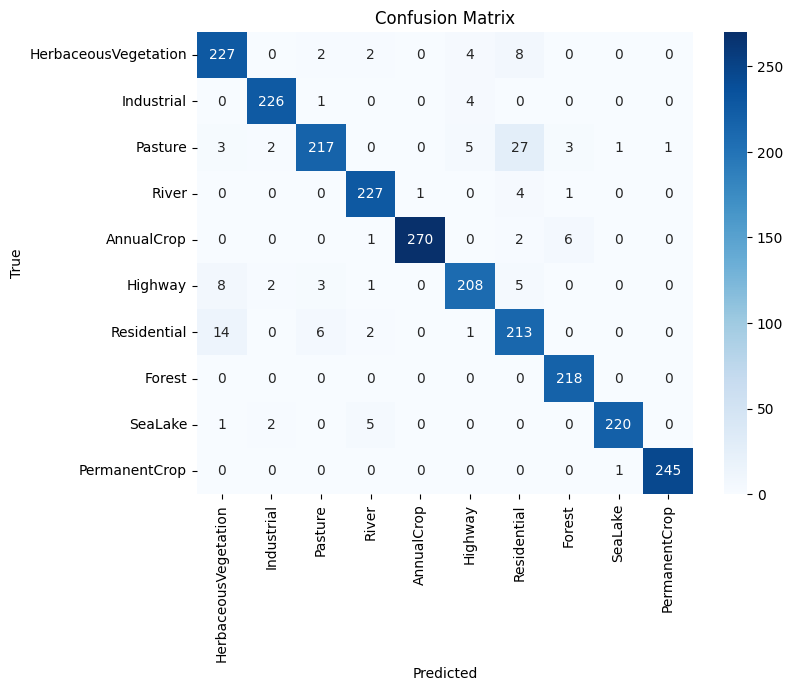

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Set the model to evaluation mode
model.eval()

# Create empty lists to store predicted and true labels
pred_labels = []
true_labels = []

# Loop through the test set and get predictions and true labels
with torch.no_grad():
    for i, (inputs, labels) in enumerate(test_data_loader):
        inputs = inputs.cuda()
        labels = labels.squeeze().long().cuda()
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        pred_labels.extend(preds.cpu().numpy())
        true_labels.extend(labels.cpu().numpy())

# Compute the confusion matrix
confusion_matrix = confusion_matrix(true_labels, pred_labels)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix, annot=True, cmap='Blues', fmt='g', xticklabels=['HerbaceousVegetation', 'Industrial', 'Pasture', 'River', 'AnnualCrop', 'Highway', 'Residential', 'Forest', 'SeaLake', 'PermanentCrop'], yticklabels=['HerbaceousVegetation', 'Industrial', 'Pasture', 'River', 'AnnualCrop', 'Highway', 'Residential', 'Forest', 'SeaLake', 'PermanentCrop'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.savefig('confusion_matrix.pdf')
plt.show()


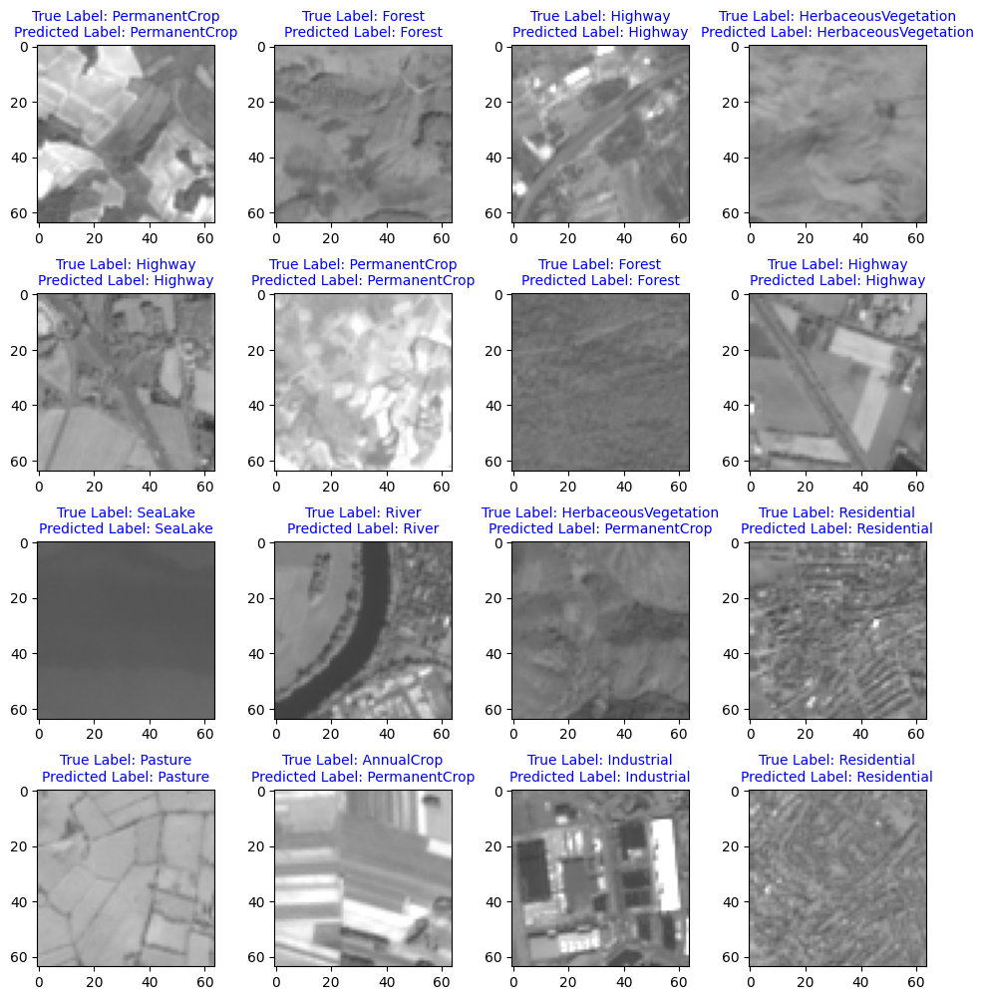

In [ ]:
# Choose 16 random samples from the test set
samples = np.random.choice(len(test_set), size=16, replace=False)

# Create a 4x4 grid of subplots to display the images
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(12, 12))

# Evaluate the model on the chosen samples and display the images with true and predicted labels
for i, ax in enumerate(axes.flat):
    image, true_label = test_set[samples[i]]
    model.eval()
    with torch.no_grad():
        output = model(image.unsqueeze(0).cuda())
    _, predicted_label = torch.max(output.data, 1)

    # Convert the image to grayscale
    gray_img = torch.mean(image, dim=0, keepdim=True)
    plot_img = gray_img.repeat(3, 1, 1)

    # Increase the brightness of the image by a factor of 4
    plot_img = np.clip(plot_img.cpu().numpy() * 4, 0, 1)

    ax.imshow(plot_img.transpose(1, 2, 0))

    # Set title with True and Predicted labels in different colors and smaller font size
    true_label_text = 'True Label: {}'.format(classes[true_label])
    predicted_label_text = 'Predicted Label: {}'.format(classes[predicted_label])
    ax.set_title('{}\n{}'.format(true_label_text, predicted_label_text), fontsize=10, color='blue')

    ax.axis('on')

plt.subplots_adjust(wspace=0.1, hspace=0.4)
plt.savefig('Test1.pdf')
plt.show()


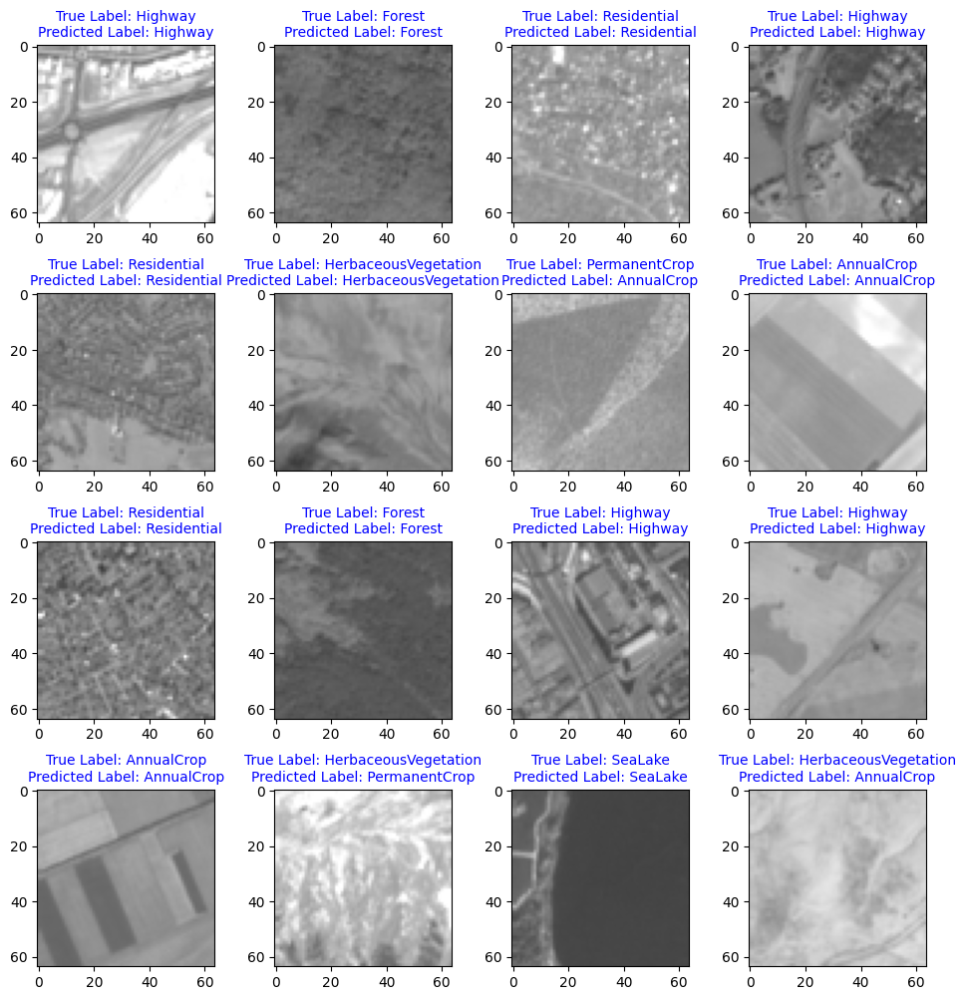

In [ ]:
# Choose 16 random samples from the test set
samples = np.random.choice(len(test_set), size=16, replace=False)

# Create a 4x4 grid of subplots to display the images
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(12, 12))

# Evaluate the model on the chosen samples and display the images with true and predicted labels
for i, ax in enumerate(axes.flat):
    image, true_label = test_set[samples[i]]
    model.eval()
    with torch.no_grad():
        output = model(image.unsqueeze(0).cuda())
    _, predicted_label = torch.max(output.data, 1)

    # Convert the image to grayscale
    gray_img = torch.mean(image, dim=0, keepdim=True)
    plot_img = gray_img.repeat(3, 1, 1)

    # Increase the brightness of the image by a factor of 4
    plot_img = np.clip(plot_img.cpu().numpy() * 4, 0, 1)

    ax.imshow(plot_img.transpose(1, 2, 0))

    # Set title with True and Predicted labels in different colors and smaller font size
    true_label_text = 'True Label: {}'.format(classes[true_label])
    predicted_label_text = 'Predicted Label: {}'.format(classes[predicted_label])
    ax.set_title('{}\n{}'.format(true_label_text, predicted_label_text), fontsize=10, color='blue')

    ax.axis('on')

plt.subplots_adjust(wspace=0.1, hspace=0.4)
plt.savefig('Test2.pdf')
plt.show()


## Continue Training...

Epoch [1/10], Train Loss: 0.0149, Train Acc: 0.9949, Val Loss: 0.2118, Val Acc: 0.9558
Epoch [2/10], Train Loss: 0.0253, Train Acc: 0.9918, Val Loss: 0.2035, Val Acc: 0.9500
Epoch [3/10], Train Loss: 0.0214, Train Acc: 0.9935, Val Loss: 0.1786, Val Acc: 0.9558
Epoch [4/10], Train Loss: 0.0155, Train Acc: 0.9951, Val Loss: 0.1924, Val Acc: 0.9479
Epoch [5/10], Train Loss: 0.0306, Train Acc: 0.9896, Val Loss: 0.1818, Val Acc: 0.9508
Epoch [6/10], Train Loss: 0.0040, Train Acc: 0.9991, Val Loss: 0.1645, Val Acc: 0.9646
Epoch [7/10], Train Loss: 0.0131, Train Acc: 0.9959, Val Loss: 0.1549, Val Acc: 0.9613
Epoch [8/10], Train Loss: 0.0013, Train Acc: 0.9997, Val Loss: 0.1534, Val Acc: 0.9654
Epoch [9/10], Train Loss: 0.0003, Train Acc: 1.0000, Val Loss: 0.1560, Val Acc: 0.9650
Epoch [10/10], Train Loss: 0.0002, Train Acc: 1.0000, Val Loss: 0.1580, Val Acc: 0.9642


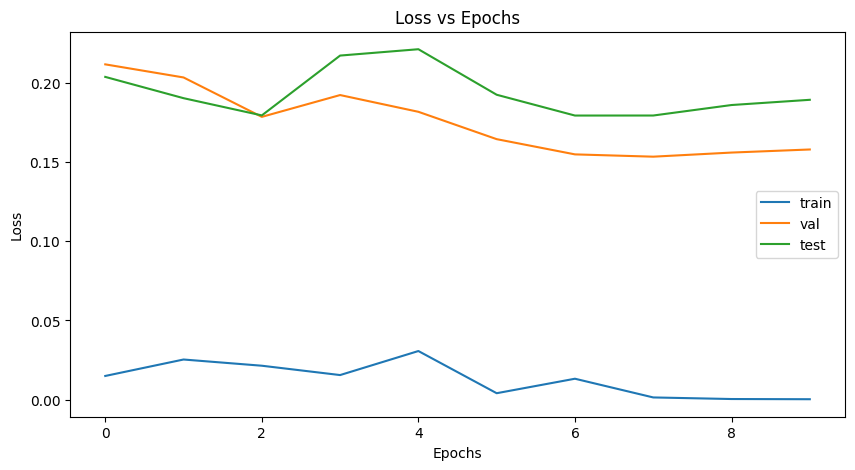

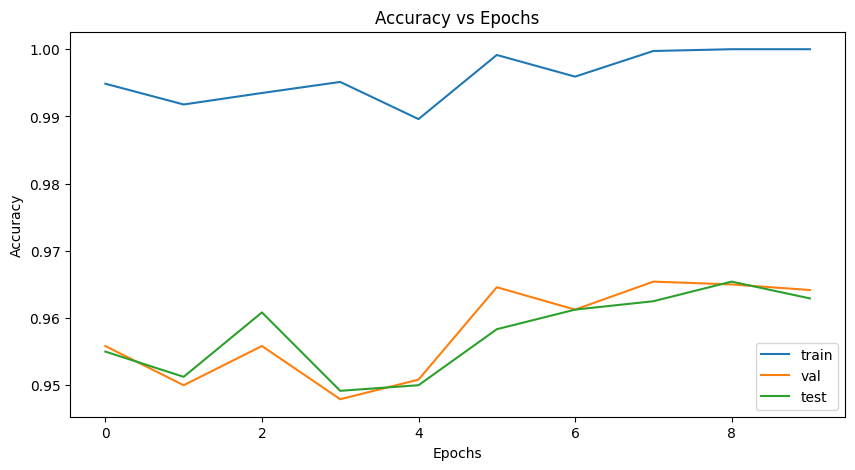

Test Accuracy: 0.9577
Test Error: 0.0423
Test Precision: 0.9579
Test Recall: 0.9577
Test F1-score: 0.9576


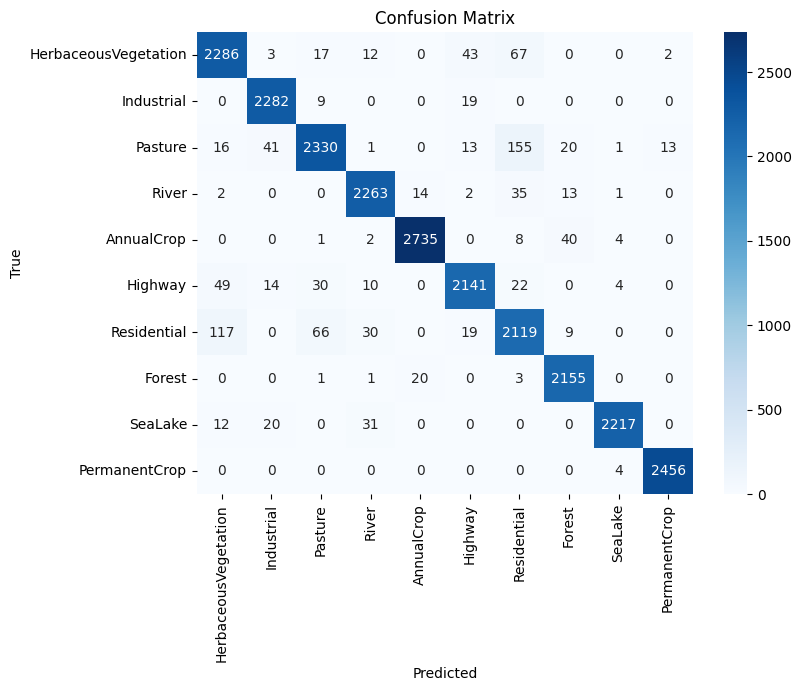

In [ ]:
# Create empty lists for storing loss and accuracy for train, val, and test
train_loss = []
train_acc = []
val_loss = []
val_acc = []
test_loss = []
test_acc = []

# Create a list to store predicted and true labels for test set
pred_labels = []
true_labels = []

num_epochs = 10

# Training loop
for epoch in range(num_epochs):
    # Train the model
    model.train()
    running_loss = 0.0
    running_corrects = 0
    total = 0
    for i, (inputs, labels) in enumerate(training_data_loader):
        inputs = inputs.cuda()
        labels = labels.squeeze().long().cuda()
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        running_corrects += torch.sum(preds == labels.data)
        total += labels.size(0)
    train_loss.append(running_loss / len(train_set))
    train_acc.append(running_corrects.double() / total)

    # Evaluate on the validation set
    model.eval()
    running_loss = 0.0
    running_corrects = 0
    total = 0
    with torch.no_grad():
        for i, (inputs, labels) in enumerate(val_data_loader):
            inputs = inputs.cuda()
            labels = labels.squeeze().long().cuda()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            running_corrects += torch.sum(preds == labels.data)
            total += labels.size(0)
    val_loss.append(running_loss / len(val_set))
    val_acc.append(running_corrects.double() / total)

    # Evaluate on the test set
    model.eval()
    running_loss = 0.0
    running_corrects = 0
    total = 0
    with torch.no_grad():
        for i, (inputs, labels) in enumerate(test_data_loader):
            inputs = inputs.cuda()
            labels = labels.squeeze().long().cuda()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            running_corrects += torch.sum(preds == labels.data)
            total += labels.size(0)
            pred_labels.extend(preds.cpu().numpy())
            true_labels.extend(labels.cpu().numpy())
    test_loss.append(running_loss / len(test_set))
    test_acc.append(running_corrects.double() / total)

    # Print epoch, loss, and accuracy for train and val sets
    print('Epoch [{}/{}], Train Loss: {:.4f}, Train Acc: {:.4f}, Val Loss: {:.4f}, Val Acc: {:.4f}'
          .format(epoch+1, num_epochs, train_loss[-1], train_acc[-1], val_loss[-1], val_acc[-1]))

# Plot the loss and accuracy curves for train, val, and test sets
plt.figure(figsize=(10, 5))
plt.plot(train_loss, label='train')
plt.plot(val_loss, label='val')
plt.plot(test_loss, label='test')
plt.title('Loss vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.savefig('loss.pdf')
plt.show()

train_acc = torch.tensor(train_acc)
val_acc = torch.tensor(val_acc)
test_acc = torch.tensor(test_acc)

# Plot the loss and accuracy curves for train, val, and test sets
plt.figure(figsize=(10, 5))
plt.plot(train_acc, label='train')
plt.plot(val_acc, label='val')
plt.plot(test_acc, label='test')
plt.title('Accuracy vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.savefig('Accuracy.pdf')
plt.show()

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

accuracy = accuracy_score(true_labels, pred_labels)
error = 1 - accuracy
precision = precision_score(true_labels, pred_labels, average='weighted')
recall = recall_score(true_labels, pred_labels, average='weighted')
f1score = f1_score(true_labels, pred_labels, average='weighted')

print('Test Accuracy: {:.4f}'.format(accuracy))
print('Test Error: {:.4f}'.format(error))
print('Test Precision: {:.4f}'.format(precision))
print('Test Recall: {:.4f}'.format(recall))
print('Test F1-score: {:.4f}'.format(f1score))

import seaborn as sns
confusion_matrix = np.zeros((10, 10))
for i in range(len(true_labels)):
  true_idx = true_labels[i]
  pred_idx = pred_labels[i]
  confusion_matrix[true_idx][pred_idx] += 1

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix, annot=True, cmap='Blues', fmt='g', xticklabels=['HerbaceousVegetation', 'Industrial', 'Pasture', 'River', 'AnnualCrop', 'Highway', 'Residential', 'Forest', 'SeaLake', 'PermanentCrop'], yticklabels=['HerbaceousVegetation', 'Industrial', 'Pasture', 'River', 'AnnualCrop', 'Highway', 'Residential', 'Forest', 'SeaLake', 'PermanentCrop'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.savefig('confusion_matrix.pdf')
plt.show()

# Save the trained model
torch.save(model.state_dict(), 'model.pth')


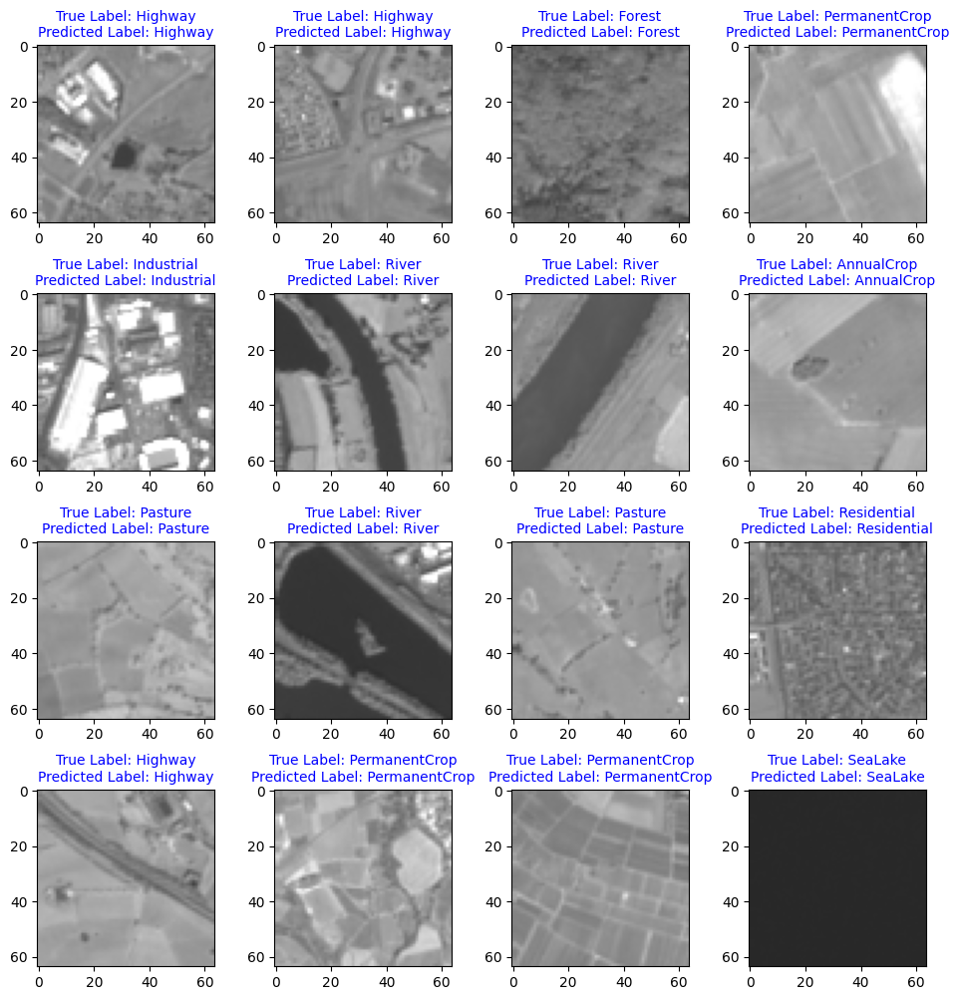

In [ ]:
# Choose 16 random samples from the test set
samples = np.random.choice(len(test_set), size=16, replace=False)

# Create a 4x4 grid of subplots to display the images
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(12, 12))

# Evaluate the model on the chosen samples and display the images with true and predicted labels
for i, ax in enumerate(axes.flat):
    image, true_label = test_set[samples[i]]
    model.eval()
    with torch.no_grad():
        output = model(image.unsqueeze(0).cuda())
    _, predicted_label = torch.max(output.data, 1)

    # Convert the image to grayscale
    gray_img = torch.mean(image, dim=0, keepdim=True)
    plot_img = gray_img.repeat(3, 1, 1)

    # Increase the brightness of the image by a factor of 4
    plot_img = np.clip(plot_img.cpu().numpy() * 4, 0, 1)

    ax.imshow(plot_img.transpose(1, 2, 0))

    # Set title with True and Predicted labels in different colors and smaller font size
    true_label_text = 'True Label: {}'.format(classes[true_label])
    predicted_label_text = 'Predicted Label: {}'.format(classes[predicted_label])
    ax.set_title('{}\n{}'.format(true_label_text, predicted_label_text), fontsize=10, color='blue')

    ax.axis('on')

plt.subplots_adjust(wspace=0.1, hspace=0.4)
plt.savefig('Test3.pdf')
plt.show()


In [ ]:
import os
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Define target directory and file path
save_dir = '/content/drive/MyDrive/HWs/HW3/Q1/Models'
os.makedirs(save_dir, exist_ok=True)

# Save the model state dictionary
torch.save(model.state_dict(), os.path.join(save_dir, 'model.pth'))

Mounted at /content/drive


In [ ]:
import shutil

source_file = 'model.pth'
destination_folder = '/content/drive/MyDrive/HWs/HW3/Q1/Models'
destination_file = 'model1.pth'

shutil.copyfile(source_file, destination_folder+'/'+destination_file)

'/content/drive/MyDrive/HWs/HW3/Q1/Models/model1.pth'

# RGB + Exactly Paper

## Show Data, Bands, ...

In [ ]:
!pip install rasterio
import os
import rasterio
import glob
import numpy as np
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
import seaborn as sn
import pandas as pd
from IPython.display import clear_output
import torch
from torch.nn import Conv2d, Linear
import torchvision.models as models
from torchsummary import summary
import torch.optim as optim
import torch.utils.data as data
from torch.utils.data import DataLoader

In [ ]:
datapath = "/content/EuroSAT/ds/images/remote_sensing/otherDatasets/sentinel_2/tif"
# Model and Trainings Parameters
batch_size = 32
threads = 6
learning_rate = 0.001
momentum = 0.9

In [ ]:
# Import necessary libraries
import os
import glob
import rasterio

# Define the path to the directory containing the raster data
datapath = "/content/EuroSAT/ds/images/remote_sensing/otherDatasets/sentinel_2/tif"

# Find all the TIFF files in the directory and its subdirectories
path_to_tiffs = glob.glob(os.path.join(datapath, "**", "*.tif"), recursive=True)

# Choose the first TIFF file as an example
tiff_file = path_to_tiffs[0]

# Open the TIFF file in read-only mode using Rasterio
with rasterio.open(tiff_file, "r") as src:

    # Read the data from the specified bands (2, 3, 4, 8) and store it in a variable (we will only work with the four 10m channels)
    tempdata = src.read((4, 2, 1))

    # Print the shape of the data array
    print("Shape of the data array:", tempdata.shape)

Shape of the data array: (3, 64, 64)


### Plot each bands to ensure we have choosen the high resoluton images.

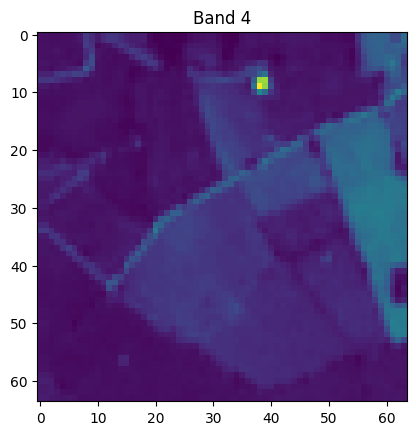

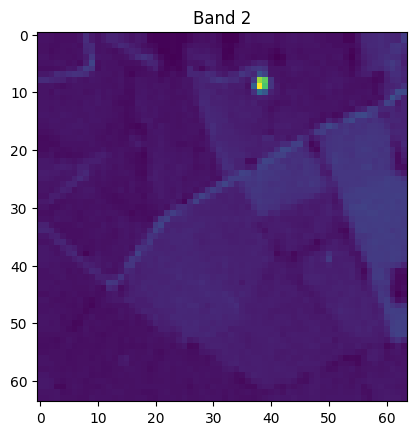

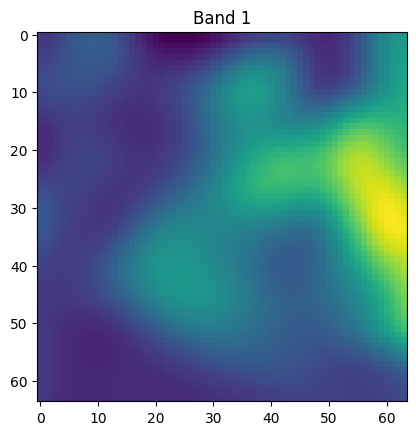

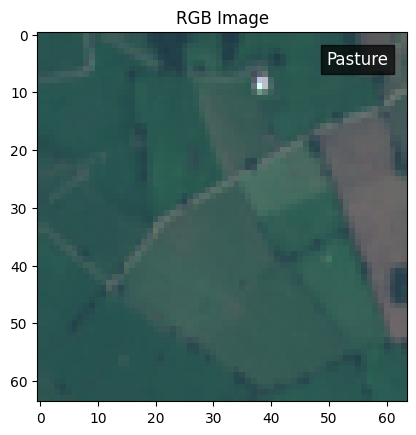

In [ ]:
import rasterio
import glob
import os
import matplotlib.pyplot as plt

# Define the path to the directory containing the data
datapath = "/content/EuroSAT/ds/images/remote_sensing/otherDatasets/sentinel_2/tif"

# Find all TIFF files in the directory and subdirectories
path_to_preview = glob.glob(os.path.join(datapath,"**","*.tif"),recursive=True)

# Read in the specified bands from the first TIFF file
with rasterio.open(path_to_preview[8000],"r") as src:
    # Note that band numbering in rasterio starts at 1, not 0
    band_nums = [4, 2, 1]
    tempdata = src.read(band_nums)

# Plot each band separately and save as a PDF file
for i, band in enumerate(tempdata, start=1):
    # Get the band number from the source file
    with rasterio.open(path_to_preview[8000],"r") as src:
        band_num = src.indexes[band_nums[i-1]-1]

    # Plot the band and set the title to the band number
    plt.imshow(band)
    plt.title("Band {}".format(band_num))

    # Save the plot as a PDF file with the band number in the filename
    plt.savefig("band{}.pdf".format(band_num))

    # Show the plot in the notebook
    plt.show()

# Display and save the RGB image
with rasterio.open(path_to_preview[8000],"r") as src:
    # Read in the red, green, and blue bands
    rgb = src.read([4,3,2])

    # Normalize the bands to values between 0 and 1
    rgb = rgb / rgb.max()

    # Display the RGB image
    fig, ax = plt.subplots()
    im = ax.imshow(rgb.transpose(1,2,0))
    plt.title("RGB Image")

    # Get the class name from the file path and add it as a legend on the top right corner
    class_name = os.path.basename(os.path.dirname(path_to_preview[8000]))
    ax.text(0.95, 0.95, class_name, transform=ax.transAxes, ha='right', va='top', color='white', fontsize=12, bbox=dict(facecolor='black', alpha=0.7, pad=4))

    # Save the RGB image as a PDF file
    plt.savefig("rgb.pdf")

    # Show the plot in the notebook
    plt.show()


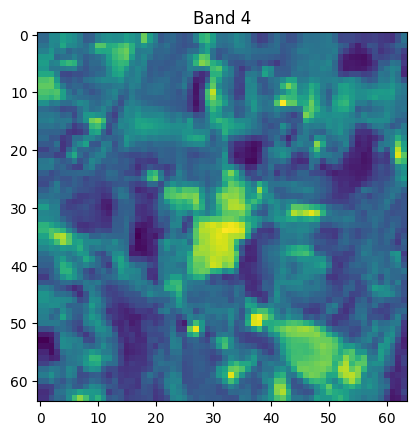

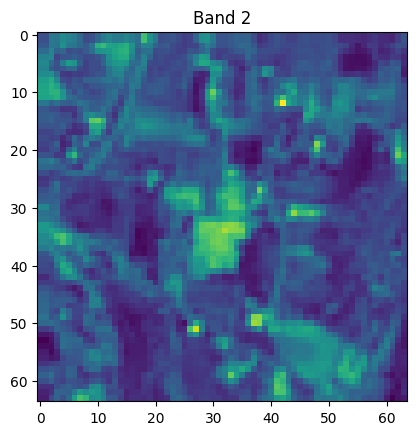

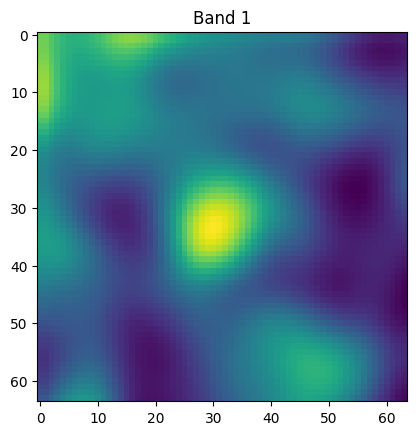

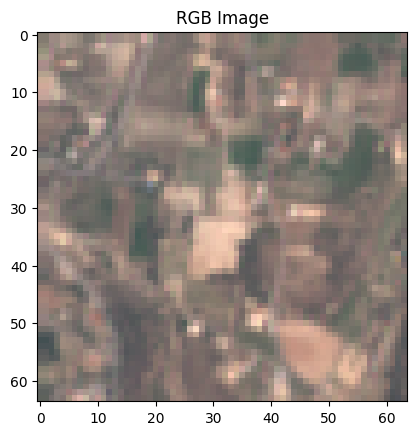

In [ ]:
import rasterio
import glob
import os
import matplotlib.pyplot as plt

# Define the path to the directory containing the data
datapath = "/content/EuroSAT/ds/images/remote_sensing/otherDatasets/sentinel_2/tif"

# Find all TIFF files in the directory and subdirectories
path_to_preview = glob.glob(os.path.join(datapath,"**","*.tif"),recursive=True)

# Read in the specified bands from the first TIFF file
with rasterio.open(path_to_preview[0],"r") as src:
    # Note that band numbering in rasterio starts at 1, not 0
    band_nums = [4, 2, 1]
    tempdata = src.read(band_nums)

# Plot each band separately and save as a PDF file
for i, band in enumerate(tempdata, start=1):
    # Get the band number from the source file
    with rasterio.open(path_to_preview[0],"r") as src:
        band_num = src.indexes[band_nums[i-1]-1]

    # Plot the band and set the title to the band number
    plt.imshow(band)
    plt.title("Band {}".format(band_num))

    # Save the plot as a PDF file with the band number in the filename
    plt.savefig("band{}.pdf".format(band_num))

    # Show the plot in the notebook
    plt.show()

# Display and save the RGB image
with rasterio.open(path_to_preview[0],"r") as src:
    # Read in the red, green, and blue bands
    rgb = src.read([4,3,2])

    # Normalize the bands to values between 0 and 1
    rgb = rgb / rgb.max()

    # Display the RGB image
    plt.imshow(rgb.transpose(1,2,0))
    plt.title("RGB Image")

    # Save the RGB image as a PDF file
    plt.savefig("rgb.pdf")

    # Show the plot in the notebook
    plt.show()


## Define Classess

In [ ]:
import os

# Get list of class names in alphabetical order
classes = (os.listdir(datapath))

# Print list of classes
print(classes)

# Check that the list of classes is not empty
assert len(classes) > 0

# Check that each class name is valid (for example, does not contain whitespace)
for class_name in classes:
    assert class_name.strip() == class_name

['PermanentCrop', 'Industrial', 'River', 'Pasture', 'HerbaceousVegetation', 'AnnualCrop', 'Residential', 'SeaLake', 'Forest', 'Highway']


In [ ]:
classes = os.listdir(datapath)
print(classes)


['PermanentCrop', 'Industrial', 'River', 'Pasture', 'HerbaceousVegetation', 'AnnualCrop', 'Residential', 'SeaLake', 'Forest', 'Highway']


In [ ]:
RS = np.random.RandomState(seed=69422)

# Sort the classes list to guarantee consistent ordering regardless of filesystem
classes = sorted(os.listdir(datapath))
assert classes == sorted(['PermanentCrop', 'Forest', 'Highway', 'Pasture', 'Industrial', 'River', 'AnnualCrop', 'HerbaceousVegetation', 'SeaLake', 'Residential'])

In [ ]:
classes

['AnnualCrop',
 'Forest',
 'HerbaceousVegetation',
 'Highway',
 'Industrial',
 'Pasture',
 'PermanentCrop',
 'Residential',
 'River',
 'SeaLake']

# Model and Train

## Define Model

### Get the model

In [ ]:
import torch
import torch.nn as nn
from torchsummary import summary

# Load the pre-trained VGG-16 model
model = models.vgg16(pretrained=True)

# Move the model to the GPU
model.cuda()

# Print the model summary
summary(model, input_size=(3, 64, 64))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 64, 64]           1,792
              ReLU-2           [-1, 64, 64, 64]               0
            Conv2d-3           [-1, 64, 64, 64]          36,928
              ReLU-4           [-1, 64, 64, 64]               0
         MaxPool2d-5           [-1, 64, 32, 32]               0
            Conv2d-6          [-1, 128, 32, 32]          73,856
              ReLU-7          [-1, 128, 32, 32]               0
            Conv2d-8          [-1, 128, 32, 32]         147,584
              ReLU-9          [-1, 128, 32, 32]               0
        MaxPool2d-10          [-1, 128, 16, 16]               0
           Conv2d-11          [-1, 256, 16, 16]         295,168
             ReLU-12          [-1, 256, 16, 16]               0
           Conv2d-13          [-1, 256, 16, 16]         590,080
             ReLU-14          [-1, 256,

### Adapt the model to our Dataset
Change first and last layer to match a four channel input and ten class classification problem

In [ ]:
import torch
import torch.nn as nn
import torchvision.models as models
from torchsummary import summary

# Load the pre-trained VGG-16 model
model = models.vgg16(pretrained=True)

# Modify the last fully connected layer to output 10 classes instead of 1000
model.classifier[-1] = nn.Linear(in_features=4096, out_features=512, bias=True)
model.classifier.add_module("dropout1", nn.Dropout(p=0.5))
model.classifier.add_module("fc2", nn.Linear(in_features=512, out_features=10, bias=True))
model.classifier.add_module("dropout2", nn.Dropout(p=0.5))

# Move the model to the GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# Print the model summary
summary(model, input_size=(3, 64, 64))


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 64, 64]           1,792
              ReLU-2           [-1, 64, 64, 64]               0
            Conv2d-3           [-1, 64, 64, 64]          36,928
              ReLU-4           [-1, 64, 64, 64]               0
         MaxPool2d-5           [-1, 64, 32, 32]               0
            Conv2d-6          [-1, 128, 32, 32]          73,856
              ReLU-7          [-1, 128, 32, 32]               0
            Conv2d-8          [-1, 128, 32, 32]         147,584
              ReLU-9          [-1, 128, 32, 32]               0
        MaxPool2d-10          [-1, 128, 16, 16]               0
           Conv2d-11          [-1, 256, 16, 16]         295,168
             ReLU-12          [-1, 256, 16, 16]               0
           Conv2d-13          [-1, 256, 16, 16]         590,080
             ReLU-14          [-1, 256,

## Functions for gathering all the images and their corresponding class labels are defined.

To create a balanced dataset, we limit the number of images per class to 2k. Alternatively, this issue could be addressed in the loss function.

In [ ]:
def get_list_of_samples(datapath):

    sample_toupels = [] # a list to hold sample-tuples

    # Loop over each class in the dataset
    for ijk, _class in enumerate(classes):

        # Get a list of all sample files for the current class
        all_samples_in_class = glob.glob(os.path.join(datapath,_class,"*.tif"))

        # Limit the number of samples to 2000 per class to create a balanced dataset
        # all_samples_in_class = all_samples_in_class[:2000]

        # Create a dictionary for each sample that includes the file path and class label
        for sample in all_samples_in_class:
            sample_toupels.append({"X":sample,"Y":ijk})

    # Return the list of dictionaries containing the image file paths and class labels
    return sample_toupels


# Train Images 20520
# Val Images 3240
# Test Images 3240


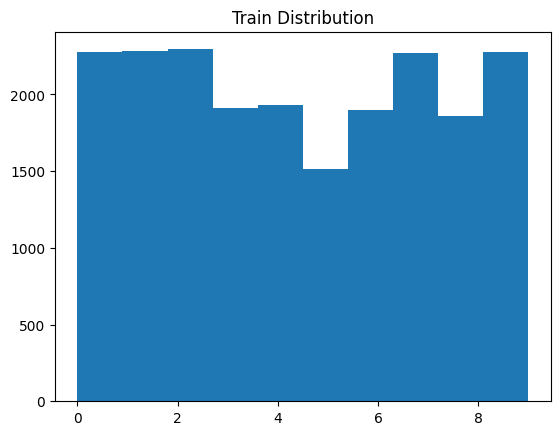

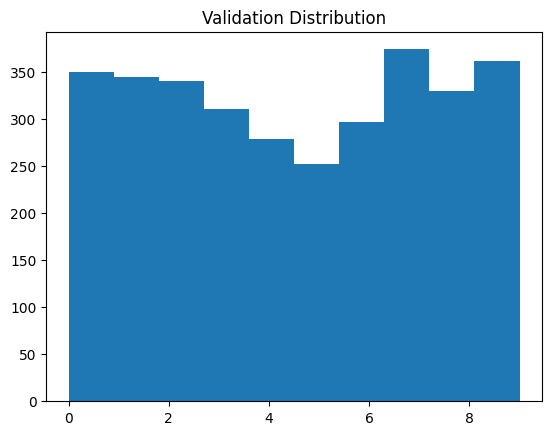

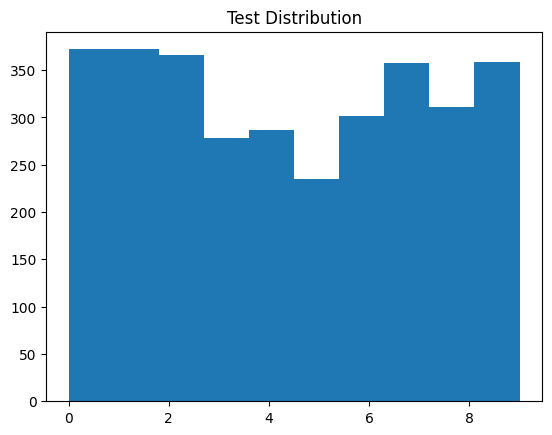

In [ ]:
import random as RS
import matplotlib.pyplot as plt

# Define a function to get a list of samples from a given datapath
# def get_list_of_samples(datapath):
#     # Code to get a list of samples from the datapath
#     pass

# Get a list of all samples from the datapath
all_samples = get_list_of_samples(datapath)

# Shuffle the samples randomly
RS.shuffle(all_samples)

# Define the ratios for train, validation, and test sets
train_ratio = 0.76
val_ratio = 0.12
test_ratio = 0.12

# Calculate the number of samples for each set based on the ratios
num_samples = len(all_samples)
num_train = int(num_samples * train_ratio)
num_val = int(num_samples * val_ratio)
num_test = num_samples - num_train - num_val

# Split the shuffled samples into train, validation, and test sets
train_locations = all_samples[:num_train]
val_locations = all_samples[num_train:num_train+num_val]
test_locations = all_samples[num_train+num_val:]

# Print the number of samples in each set
print("# Train Images", len(train_locations))
print("# Val Images", len(val_locations))
print("# Test Images", len(test_locations))

# Plot the distribution of the Y values for the train set and save as a PDF
temp_hist = []
for d in train_locations:
    temp_hist.append(d["Y"])
plt.hist(temp_hist)
plt.title("Train Distribution")
plt.savefig("traindistribution.pdf")
plt.show()

# Plot the distribution of the Y values for the validation set and save as a PDF
temp_hist = []
for d in val_locations:
    temp_hist.append(d["Y"])
plt.hist(temp_hist)
plt.title("Validation Distribution")
plt.savefig("validationdistribution.pdf")
plt.show()

# Plot the distribution of the Y values for the test set and save as a PDF
temp_hist = []
for d in test_locations:
    temp_hist.append(d["Y"])
plt.hist(temp_hist)
plt.title("Test Distribution")
plt.savefig("testdistribution.pdf")
plt.show()


## Dataloader

In [ ]:
import rasterio
import numpy as np
import torch
from torch.utils import data
from torch.utils.data import DataLoader
import warnings
warnings.filterwarnings("ignore")

# Define a dataset class for the Super Resolution (SR) model
class class_dataset(data.Dataset):

    # Constructor to initialize the samplelist for the dataset
    def __init__(self, samplelist):
        self.samplelist = samplelist

    # Method to get the data and label tensors for a given index
    def __getitem__(self, i):

        # Open the image file using rasterio
        with rasterio.open(self.samplelist[i]["X"], "r") as src:

            # Read the data from bands 2, 3, 4, and 8 as a float32 array
            data = src.read((4, 2, 1)).astype("float32")

            # Normalize the data to [0,1] range
            data = data / 10000

            # Clip the data to [0,1] range
            data = np.clip(data, 0, 1)

        # Return the data tensor and the label tensor as a tuple
        return torch.Tensor(data), torch.Tensor([self.samplelist[i]["Y"]]).long()

    # Method to get the length of the dataset
    def __len__(self):
        return len(self.samplelist)

# Create datasets and dataloaders for train, validation, and test sets
train_set = class_dataset(train_locations)
val_set = class_dataset(val_locations)
test_set = class_dataset(test_locations)

# Setup the dataloader with the given number of worker threads, batch size, and shuffle option
training_data_loader = DataLoader(dataset=train_set, num_workers=threads, batch_size=batch_size, shuffle=True, drop_last=True)
val_data_loader = DataLoader(dataset=val_set, num_workers=threads, batch_size=batch_size, shuffle=True, drop_last=True)
test_data_loader = DataLoader(dataset=test_set, num_workers=threads, batch_size=batch_size, shuffle=True, drop_last=True)

### Show one batch

torch.Size([32, 3, 64, 64]) torch.Size([32, 1])


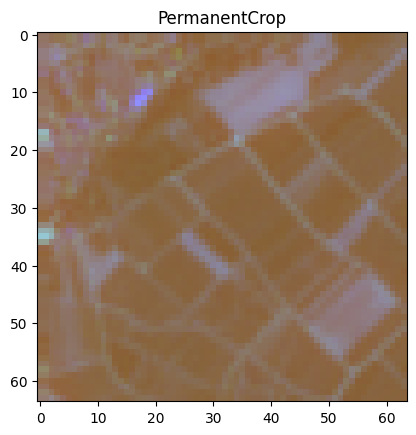

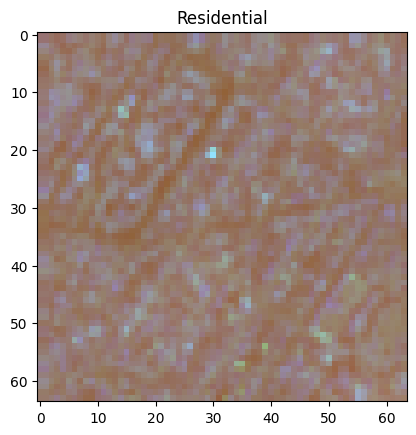

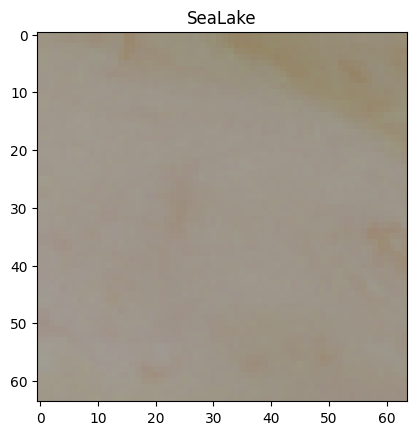

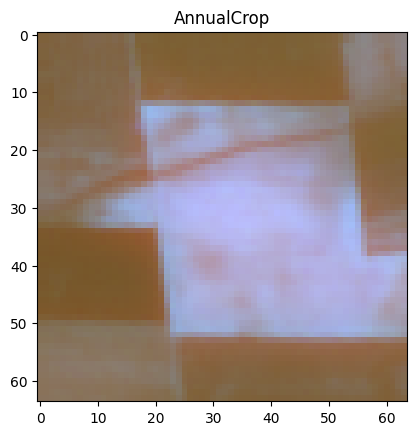

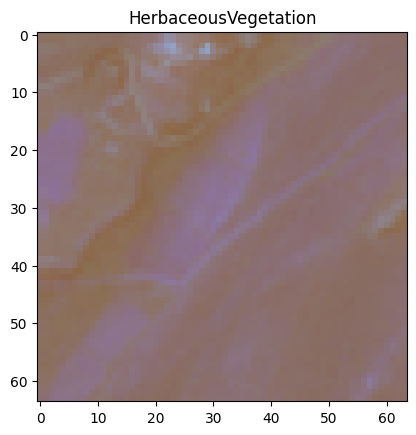

...

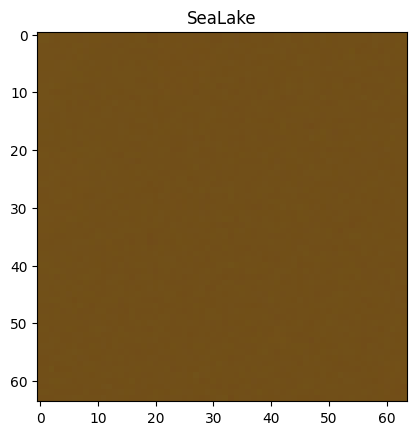

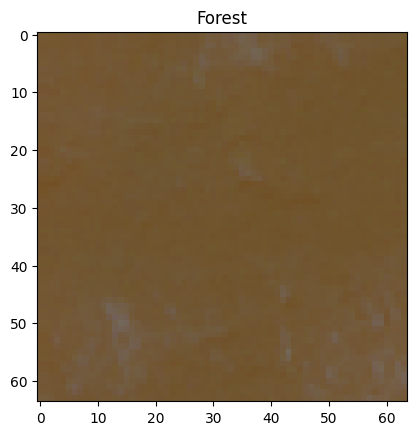

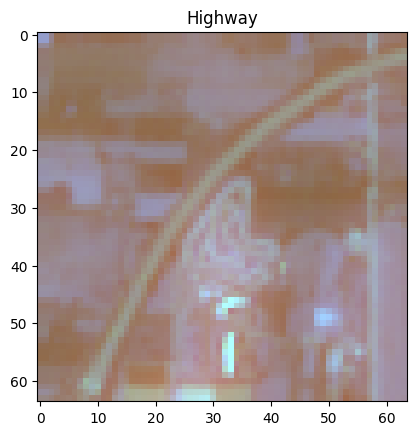

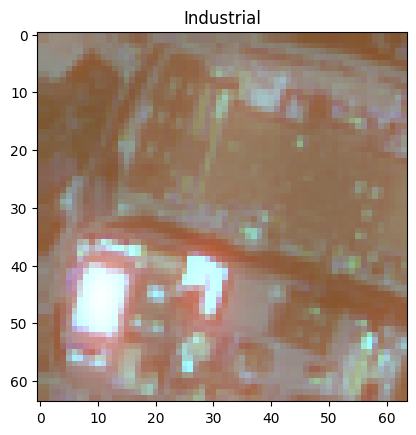

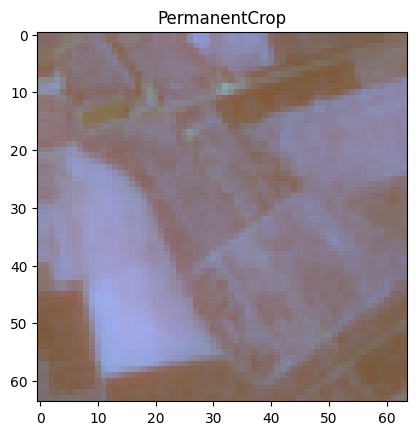

In [ ]:
# Loop over the first batch of images and their corresponding labels
for img, label in val_data_loader:
    # Only process the first batch
    break

# Print the shape of the first image and its label
print(img.shape,label.shape)

# Loop over each image in the batch
for batchindex in range(batch_size):

    # Extract the B, G, R color channels from the image
    B,G,R = img[batchindex,:3,:,:]
    # Stack the channels to form a colored image
    plot_img = np.stack([R,G,B],axis=-1)
    # Increase the brightness of the image by a factor of 4
    plot_img = np.clip(plot_img*4,0,1)

    # Display the image along with its corresponding label
    plt.imshow(plot_img)
    plt.title(classes[label[batchindex].numpy()[0]])
    plt.show()

torch.Size([32, 3, 64, 64]) torch.Size([32, 1])


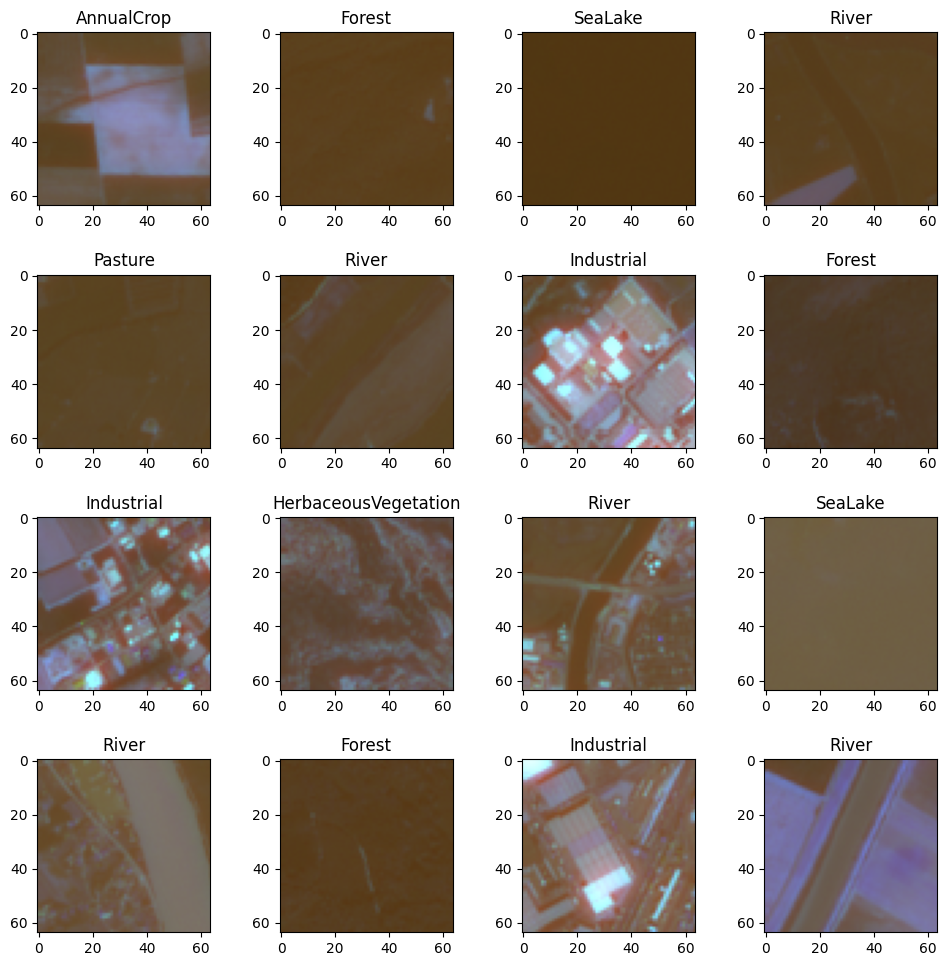

In [ ]:
# Loop over the first batch of images and their corresponding labels
for img, label in val_data_loader:
    # Only process the first batch
    break

# Print the shape of the first image and its label
print(img.shape,label.shape)

# Create a 4x4 grid for the images with margins of 0.2 on all sides
fig, axs = plt.subplots(4, 4, figsize=(10,10))
fig.subplots_adjust(hspace=0.4, wspace=0.4, top=0.95, bottom=0.05, left=0.05, right=0.95)

# Loop over each image in the batch
for batchindex in range(batch_size):

    # Extract the B, G, R color channels from the image
    B,G,R = img[batchindex,:3,:,:]
    # Stack the channels to form a colored image
    plot_img = np.stack([R,G,B],axis=-1)
    # Increase the brightness of the image by a factor of 3
    plot_img = np.clip(plot_img*3,0,1)

    # Display the image along with its corresponding label in the grid
    row = batchindex // 8
    col = batchindex % 4
    axs[row, col].imshow(plot_img)
    axs[row, col].set_title(classes[label[batchindex].numpy()[0]])

# Set the title of the plot
# fig.suptitle('First batch of validation images')
# Hide the x and y axis labels for all subplots
for ax in axs.flat:
    ax.set(xlabel='', ylabel='')
# Save the plot
plt.savefig('batchimages.pdf')
# Show the plot
plt.show()

# Training

## Setup Model and Trainings Parameters

In [ ]:
# Define model and training parameters
batch_size = 32  # Batch size for training
threads = 6  # Number of threads for data loading
learning_rate = 0.001  # Learning rate for the optimizer
momentum = 0.9  # Momentum factor for the optimizer

# Define loss function and optimizer
criterion = torch.nn.CrossEntropyLoss()  # Cross-entropy loss function
optimizer = optim.SGD(model.parameters(), lr=learning_rate, momentum=momentum)  # Stochastic Gradient Descent optimizer with specified learning rate and momentum

## Main Trainings Code

Epoch [1/20], Train Loss: 1.5001, Train Acc: 0.4453, Val Loss: 0.6278, Val Acc: 0.8311
Epoch [2/20], Train Loss: 1.1740, Train Acc: 0.5402, Val Loss: 0.4443, Val Acc: 0.8716
Epoch [3/20], Train Loss: 1.0871, Train Acc: 0.5625, Val Loss: 0.4064, Val Acc: 0.8911
Epoch [4/20], Train Loss: 1.0251, Train Acc: 0.5732, Val Loss: 0.2820, Val Acc: 0.9236
Epoch [5/20], Train Loss: 0.9848, Train Acc: 0.5803, Val Loss: 0.2525, Val Acc: 0.9285
Epoch [6/20], Train Loss: 0.9571, Train Acc: 0.5840, Val Loss: 0.2151, Val Acc: 0.9381
Epoch [7/20], Train Loss: 0.9563, Train Acc: 0.5829, Val Loss: 0.2266, Val Acc: 0.9381
Epoch [8/20], Train Loss: 0.9241, Train Acc: 0.5972, Val Loss: 0.1891, Val Acc: 0.9409
Epoch [9/20], Train Loss: 0.9237, Train Acc: 0.5904, Val Loss: 0.1867, Val Acc: 0.9437
Epoch [10/20], Train Loss: 0.8899, Train Acc: 0.6012, Val Loss: 0.1671, Val Acc: 0.9508
Epoch [11/20], Train Loss: 0.8993, Train Acc: 0.5941, Val Loss: 0.2013, Val Acc: 0.9449
Epoch [12/20], Train Loss: 0.9012, Train 

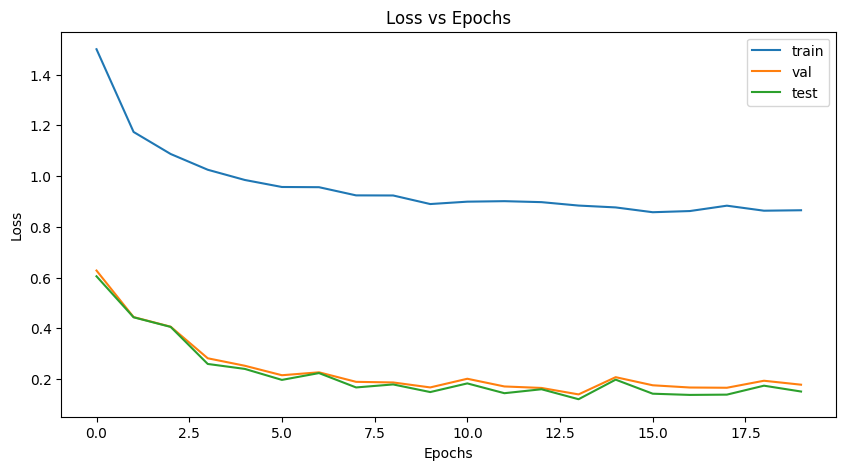

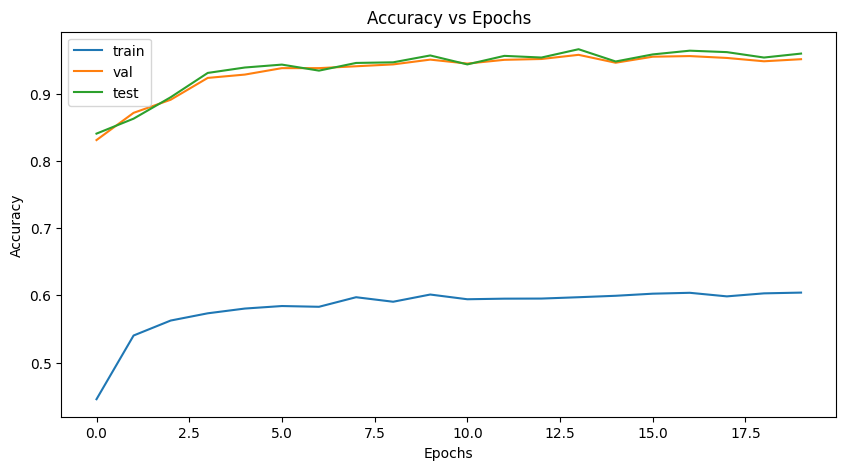

Test Accuracy: 0.9381
Test Error: 0.0619
Test Precision: 0.9383
Test Recall: 0.9381
Test F1-score: 0.9377


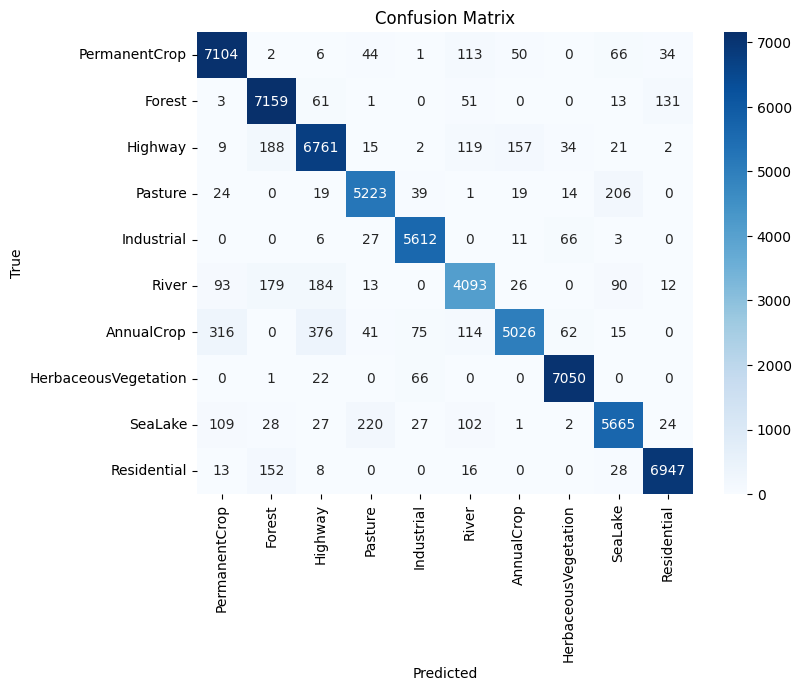

In [ ]:
# Create empty lists for storing loss and accuracy for train, val, and test
train_loss = []
train_acc = []
val_loss = []
val_acc = []
test_loss = []
test_acc = []

# Create a list to store predicted and true labels for test set
pred_labels = []
true_labels = []

num_epochs = 20

# Training loop
for epoch in range(num_epochs):
    # Train the model
    model.train()
    running_loss = 0.0
    running_corrects = 0
    total = 0
    for i, (inputs, labels) in enumerate(training_data_loader):
        inputs = inputs.cuda()
        labels = labels.squeeze().long().cuda()
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        running_corrects += torch.sum(preds == labels.data)
        total += labels.size(0)
    train_loss.append(running_loss / len(train_set))
    train_acc.append(running_corrects.double() / total)

    # Evaluate on the validation set
    model.eval()
    running_loss = 0.0
    running_corrects = 0
    total = 0
    with torch.no_grad():
        for i, (inputs, labels) in enumerate(val_data_loader):
            inputs = inputs.cuda()
            labels = labels.squeeze().long().cuda()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            running_corrects += torch.sum(preds == labels.data)
            total += labels.size(0)
    val_loss.append(running_loss / len(val_set))
    val_acc.append(running_corrects.double() / total)

    # Evaluate on the test set
    model.eval()
    running_loss = 0.0
    running_corrects = 0
    total = 0
    with torch.no_grad():
        for i, (inputs, labels) in enumerate(test_data_loader):
            inputs = inputs.cuda()
            labels = labels.squeeze().long().cuda()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            running_corrects += torch.sum(preds == labels.data)
            total += labels.size(0)
            pred_labels.extend(preds.cpu().numpy())
            true_labels.extend(labels.cpu().numpy())
    test_loss.append(running_loss / len(test_set))
    test_acc.append(running_corrects.double() / total)

    # Print epoch, loss, and accuracy for train and val sets
    print('Epoch [{}/{}], Train Loss: {:.4f}, Train Acc: {:.4f}, Val Loss: {:.4f}, Val Acc: {:.4f}'
          .format(epoch+1, num_epochs, train_loss[-1], train_acc[-1], val_loss[-1], val_acc[-1]))

# Plot the loss and accuracy curves for train, val, and test sets
plt.figure(figsize=(10, 5))
plt.plot(train_loss, label='train')
plt.plot(val_loss, label='val')
plt.plot(test_loss, label='test')
plt.title('Loss vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.savefig('loss.pdf')
plt.show()

train_acc = torch.tensor(train_acc)
val_acc = torch.tensor(val_acc)
test_acc = torch.tensor(test_acc)

# Plot the loss and accuracy curves for train, val, and test sets
plt.figure(figsize=(10, 5))
plt.plot(train_acc, label='train')
plt.plot(val_acc, label='val')
plt.plot(test_acc, label='test')
plt.title('Accuracy vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.savefig('Accuracy.pdf')
plt.show()

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

accuracy = accuracy_score(true_labels, pred_labels)
error = 1 - accuracy
precision = precision_score(true_labels, pred_labels, average='weighted')
recall = recall_score(true_labels, pred_labels, average='weighted')
f1score = f1_score(true_labels, pred_labels, average='weighted')

print('Test Accuracy: {:.4f}'.format(accuracy))
print('Test Error: {:.4f}'.format(error))
print('Test Precision: {:.4f}'.format(precision))
print('Test Recall: {:.4f}'.format(recall))
print('Test F1-score: {:.4f}'.format(f1score))

import seaborn as sns
confusion_matrix = np.zeros((10, 10))
for i in range(len(true_labels)):
  true_idx = true_labels[i]
  pred_idx = pred_labels[i]
  confusion_matrix[true_idx][pred_idx] += 1

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix, annot=True, cmap='Blues', fmt='g', xticklabels=['PermanentCrop', 'Forest', 'Highway', 'Pasture', 'Industrial', 'River', 'AnnualCrop', 'HerbaceousVegetation', 'SeaLake', 'Residential'], yticklabels=['PermanentCrop', 'Forest', 'Highway', 'Pasture', 'Industrial', 'River', 'AnnualCrop', 'HerbaceousVegetation', 'SeaLake', 'Residential'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.savefig('confusion_matrix.pdf')
plt.show()

# Save the trained model
torch.save(model.state_dict(), 'model.pth')


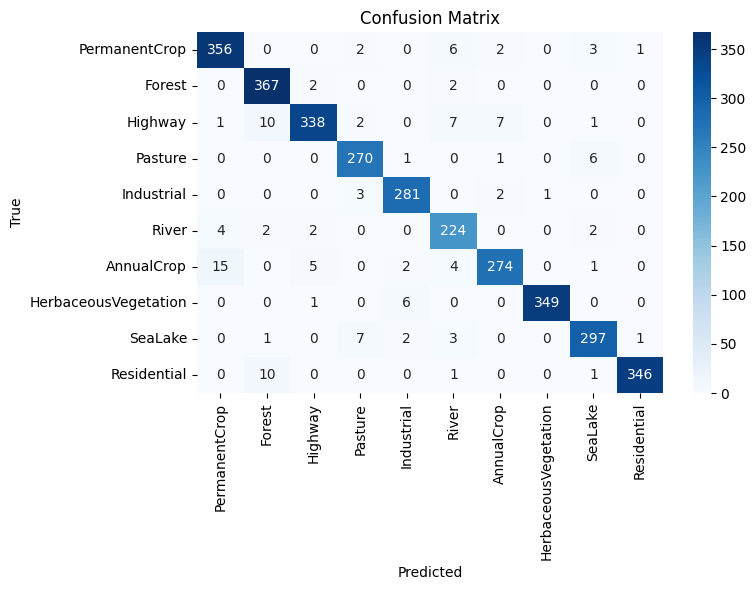

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Set the model to evaluation mode
model.eval()

# Create empty lists to store predicted and true labels
pred_labels = []
true_labels = []

# Loop through the test set and get predictions and true labels
with torch.no_grad():
    for i, (inputs, labels) in enumerate(test_data_loader):
        inputs = inputs.cuda()
        labels = labels.squeeze().long().cuda()
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        pred_labels.extend(preds.cpu().numpy())
        true_labels.extend(labels.cpu().numpy())

from matplotlib.backends.backend_pdf import PdfPages

# Compute the confusion matrix
confusion_matrix = confusion_matrix(true_labels, pred_labels)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix, annot=True, cmap='Blues', fmt='g', xticklabels=['PermanentCrop', 'Forest', 'Highway', 'Pasture', 'Industrial', 'River', 'AnnualCrop', 'HerbaceousVegetation', 'SeaLake', 'Residential'], yticklabels=['PermanentCrop', 'Forest', 'Highway', 'Pasture', 'Industrial', 'River', 'AnnualCrop', 'HerbaceousVegetation', 'SeaLake', 'Residential'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.tight_layout()

# Save the figure to a PDF file
with PdfPages('confusion_matrix11.pdf') as pdf:
    pdf.savefig(bbox_inches='tight')
    plt.show()

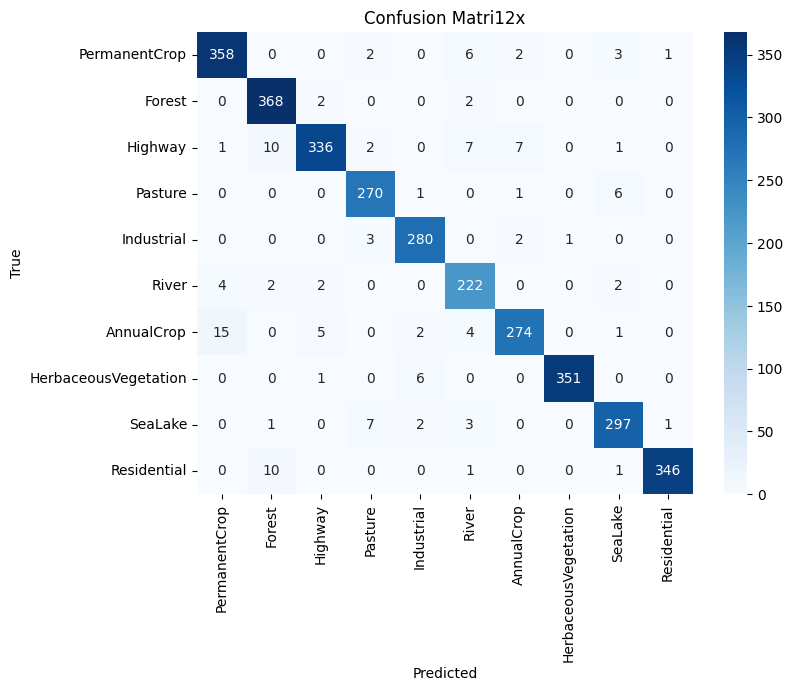

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Set the model to evaluation mode
model.eval()

# Create empty lists to store predicted and true labels
pred_labels = []
true_labels = []

# Loop through the test set and get predictions and true labels
with torch.no_grad():
    for i, (inputs, labels) in enumerate(test_data_loader):
        inputs = inputs.cuda()
        labels = labels.squeeze().long().cuda()
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        pred_labels.extend(preds.cpu().numpy())
        true_labels.extend(labels.cpu().numpy())

# Compute the confusion matrix
confusion_matrix = confusion_matrix(true_labels, pred_labels)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix, annot=True, cmap='Blues', fmt='g', xticklabels=['PermanentCrop', 'Forest', 'Highway', 'Pasture', 'Industrial', 'River', 'AnnualCrop', 'HerbaceousVegetation', 'SeaLake', 'Residential'], yticklabels=['PermanentCrop', 'Forest', 'Highway', 'Pasture', 'Industrial', 'River', 'AnnualCrop', 'HerbaceousVegetation', 'SeaLake', 'Residential'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matri12x')
plt.savefig('confusion_matrix.pdf')
plt.show()


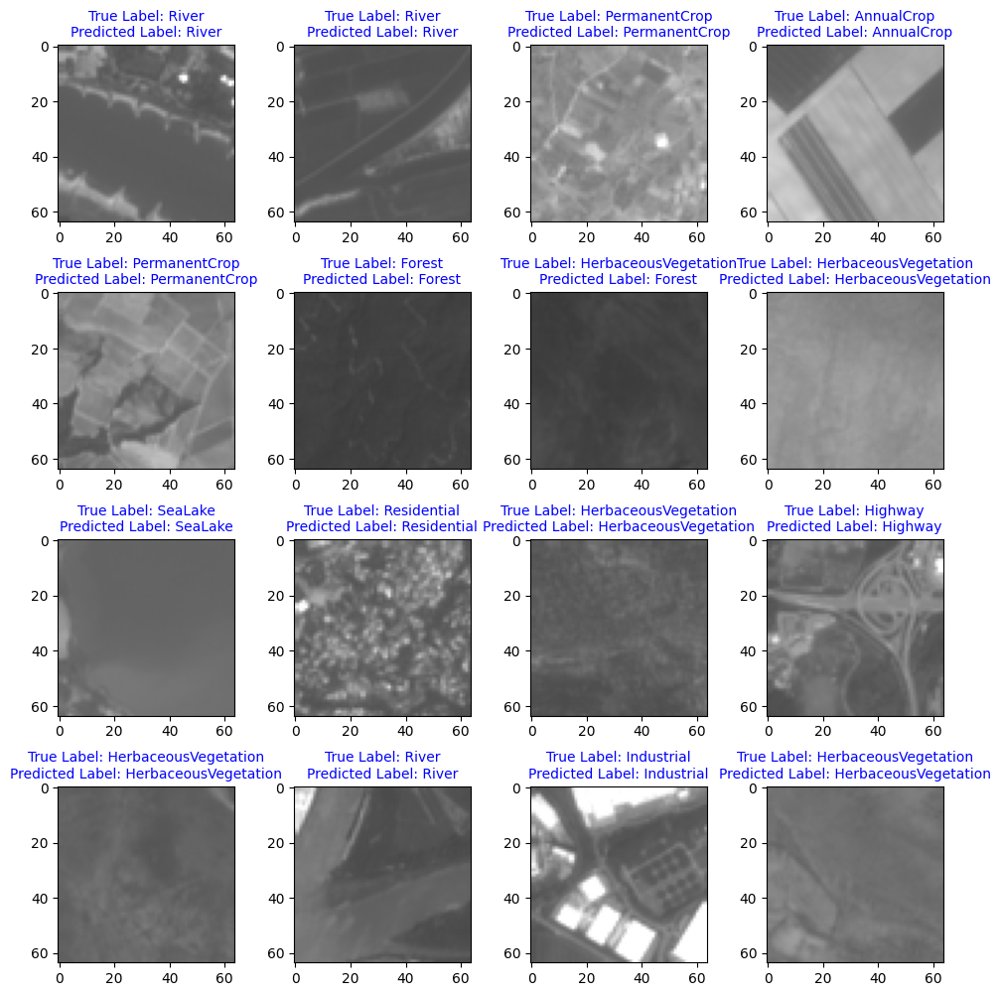

In [ ]:
# Choose 16 random samples from the test set
samples = np.random.choice(len(test_set), size=16, replace=False)

# Create a 4x4 grid of subplots to display the images
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(12, 12))

# Evaluate the model on the chosen samples and display the images with true and predicted labels
for i, ax in enumerate(axes.flat):
    image, true_label = test_set[samples[i]]
    model.eval()
    with torch.no_grad():
        output = model(image.unsqueeze(0).cuda())
    _, predicted_label = torch.max(output.data, 1)

    # Convert the image to grayscale
    gray_img = torch.mean(image, dim=0, keepdim=True)
    plot_img = gray_img.repeat(3, 1, 1)

    # Increase the brightness of the image by a factor of 4
    plot_img = np.clip(plot_img.cpu().numpy() * 4, 0, 1)

    ax.imshow(plot_img.transpose(1, 2, 0))

    # Set title with True and Predicted labels in different colors and smaller font size
    true_label_text = 'True Label: {}'.format(classes[true_label])
    predicted_label_text = 'Predicted Label: {}'.format(classes[predicted_label])
    ax.set_title('{}\n{}'.format(true_label_text, predicted_label_text), fontsize=10, color='blue')

    ax.axis('on')

plt.subplots_adjust(wspace=0.1, hspace=0.4)
plt.savefig('Test1.pdf')
plt.show()


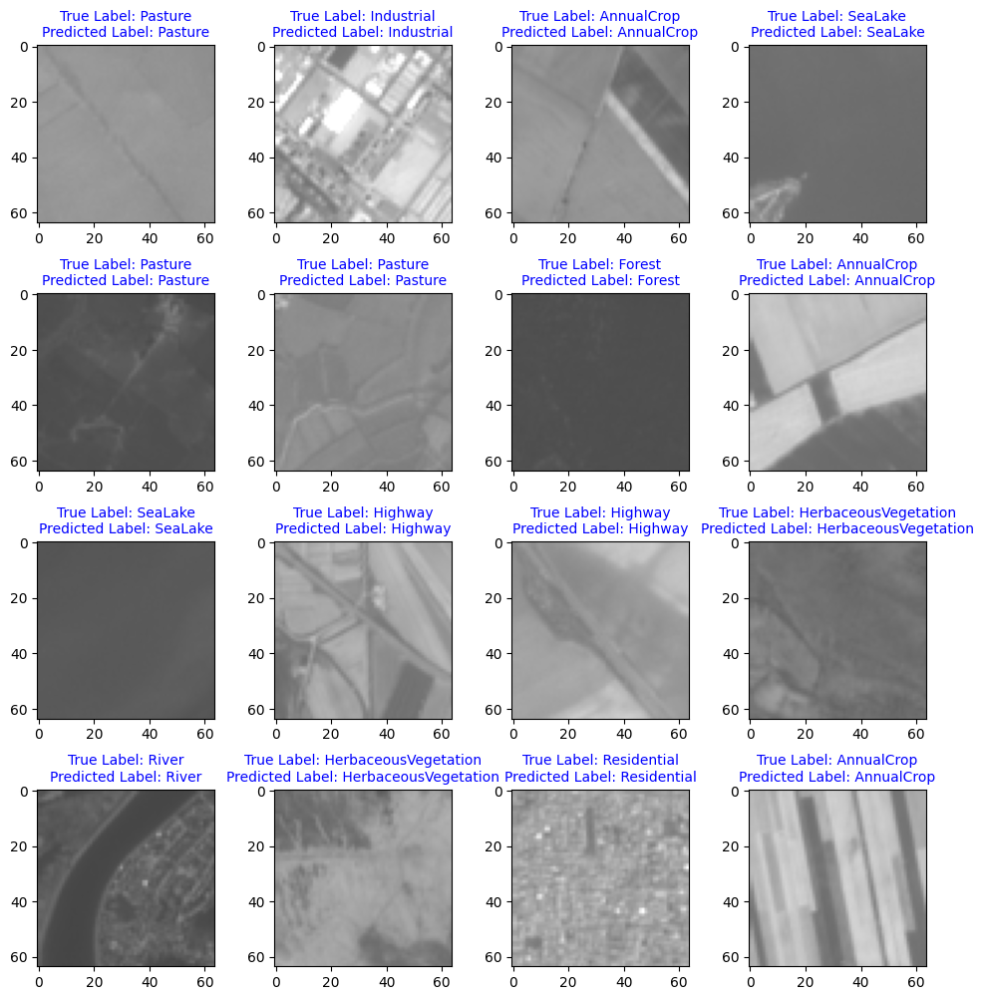

In [ ]:
# Choose 16 random samples from the test set
samples = np.random.choice(len(test_set), size=16, replace=False)

# Create a 4x4 grid of subplots to display the images
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(12, 12))

# Evaluate the model on the chosen samples and display the images with true and predicted labels
for i, ax in enumerate(axes.flat):
    image, true_label = test_set[samples[i]]
    model.eval()
    with torch.no_grad():
        output = model(image.unsqueeze(0).cuda())
    _, predicted_label = torch.max(output.data, 1)

    # Convert the image to grayscale
    gray_img = torch.mean(image, dim=0, keepdim=True)
    plot_img = gray_img.repeat(3, 1, 1)

    # Increase the brightness of the image by a factor of 4
    plot_img = np.clip(plot_img.cpu().numpy() * 4, 0, 1)

    ax.imshow(plot_img.transpose(1, 2, 0))

    # Set title with True and Predicted labels in different colors and smaller font size
    true_label_text = 'True Label: {}'.format(classes[true_label])
    predicted_label_text = 'Predicted Label: {}'.format(classes[predicted_label])
    ax.set_title('{}\n{}'.format(true_label_text, predicted_label_text), fontsize=10, color='blue')

    ax.axis('on')

plt.subplots_adjust(wspace=0.1, hspace=0.4)
plt.savefig('Test2.pdf')
plt.show()


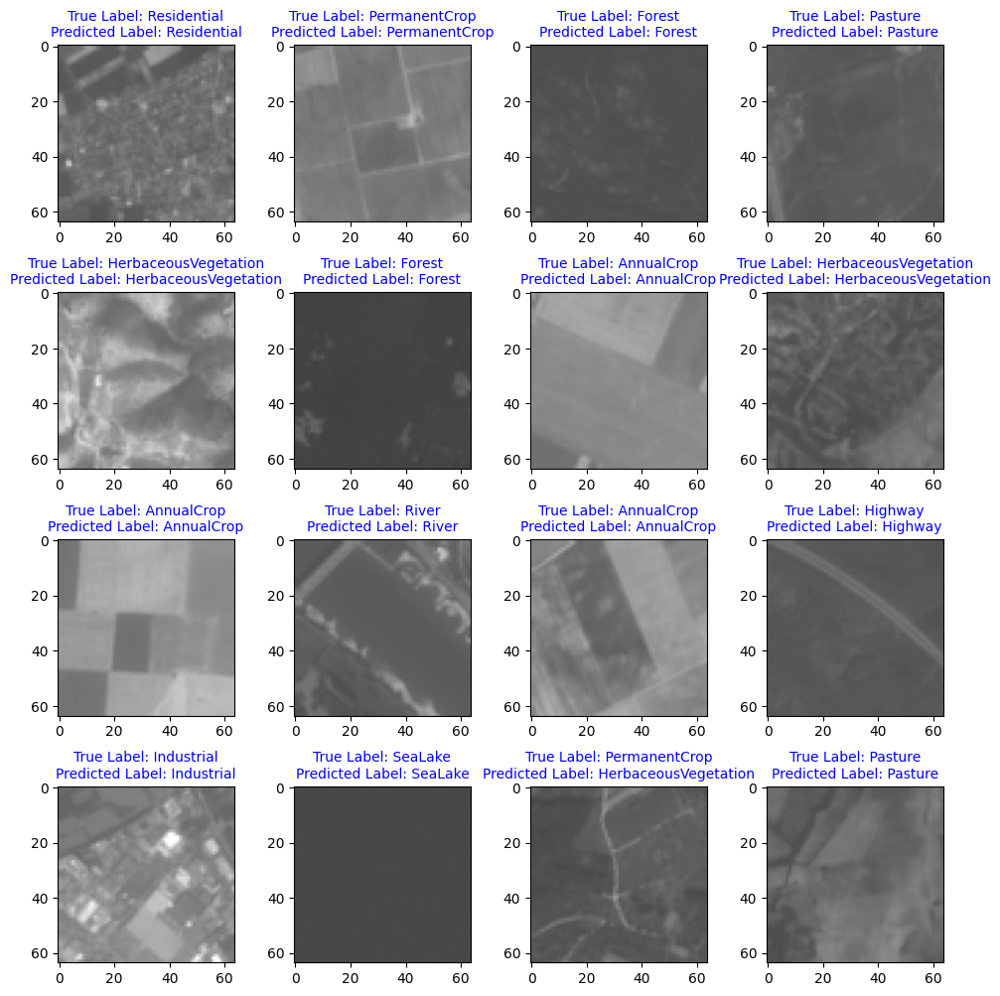

In [ ]:
# Choose 16 random samples from the test set
samples = np.random.choice(len(test_set), size=16, replace=False)

# Create a 4x4 grid of subplots to display the images
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(12, 12))

# Evaluate the model on the chosen samples and display the images with true and predicted labels
for i, ax in enumerate(axes.flat):
    image, true_label = test_set[samples[i]]
    model.eval()
    with torch.no_grad():
        output = model(image.unsqueeze(0).cuda())
    _, predicted_label = torch.max(output.data, 1)

    # Convert the image to grayscale
    gray_img = torch.mean(image, dim=0, keepdim=True)
    plot_img = gray_img.repeat(3, 1, 1)

    # Increase the brightness of the image by a factor of 4
    plot_img = np.clip(plot_img.cpu().numpy() * 4, 0, 1)

    ax.imshow(plot_img.transpose(1, 2, 0))

    # Set title with True and Predicted labels in different colors and smaller font size
    true_label_text = 'True Label: {}'.format(classes[true_label])
    predicted_label_text = 'Predicted Label: {}'.format(classes[predicted_label])
    ax.set_title('{}\n{}'.format(true_label_text, predicted_label_text), fontsize=10, color='blue')

    ax.axis('on')

plt.subplots_adjust(wspace=0.1, hspace=0.4)
plt.savefig('Test3.pdf')
plt.show()


# Other Implementations!

Epoch [1/30], Train Loss: 0.8772, Train Acc: 0.5935, Val Loss: 0.2503, Val Acc: 0.9341
Epoch [2/30], Train Loss: 0.8519, Train Acc: 0.6083, Val Loss: 0.1616, Val Acc: 0.9567
Epoch [3/30], Train Loss: 0.8478, Train Acc: 0.6069, Val Loss: 0.1703, Val Acc: 0.9595
Epoch [4/30], Train Loss: 0.8478, Train Acc: 0.6089, Val Loss: 0.1984, Val Acc: 0.9517
Epoch [5/30], Train Loss: 0.8638, Train Acc: 0.6021, Val Loss: 0.1723, Val Acc: 0.9530
Epoch [6/30], Train Loss: 0.8396, Train Acc: 0.6101, Val Loss: 0.1718, Val Acc: 0.9576
Epoch [7/30], Train Loss: 0.8527, Train Acc: 0.6010, Val Loss: 0.1656, Val Acc: 0.9619
Epoch [8/30], Train Loss: 0.8434, Train Acc: 0.6064, Val Loss: 0.1666, Val Acc: 0.9564
Epoch [9/30], Train Loss: 0.8450, Train Acc: 0.6033, Val Loss: 0.1647, Val Acc: 0.9598
Epoch [10/30], Train Loss: 0.8671, Train Acc: 0.6025, Val Loss: 0.2340, Val Acc: 0.9425
Epoch [11/30], Train Loss: 0.8488, Train Acc: 0.6070, Val Loss: 0.1530, Val Acc: 0.9610
Epoch [12/30], Train Loss: 0.8434, Train 

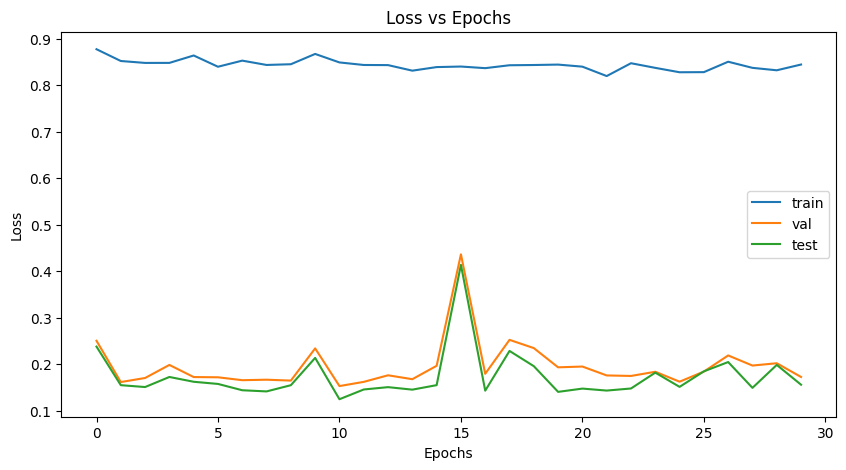

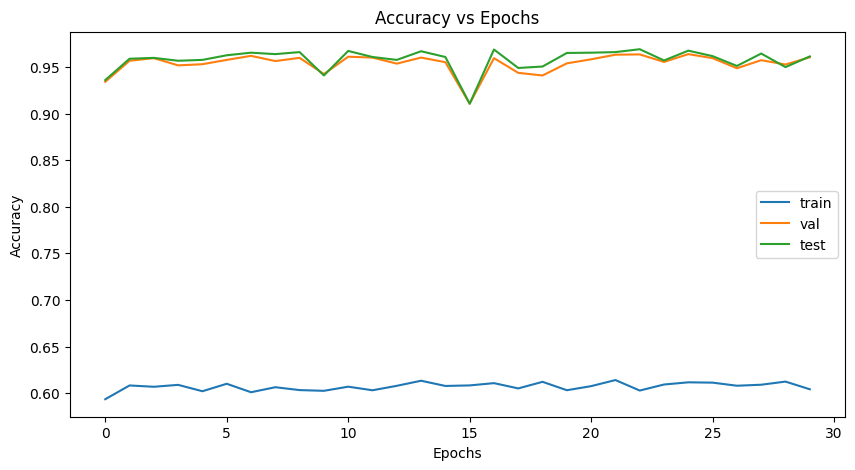

Test Accuracy: 0.9579
Test Error: 0.0421
Test Precision: 0.9580
Test Recall: 0.9579
Test F1-score: 0.9578


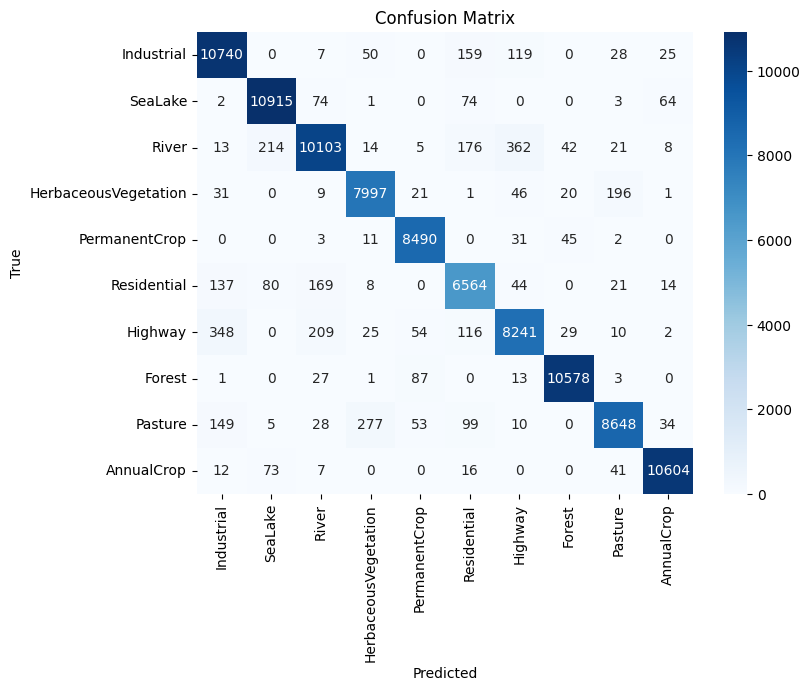

In [ ]:
# Create empty lists for storing loss and accuracy for train, val, and test
train_loss = []
train_acc = []
val_loss = []
val_acc = []
test_loss = []
test_acc = []

# Create a list to store predicted and true labels for test set
pred_labels = []
true_labels = []

num_epochs = 30

# Training loop
for epoch in range(num_epochs):
    # Train the model
    model.train()
    running_loss = 0.0
    running_corrects = 0
    total = 0
    for i, (inputs, labels) in enumerate(training_data_loader):
        inputs = inputs.cuda()
        labels = labels.squeeze().long().cuda()
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        running_corrects += torch.sum(preds == labels.data)
        total += labels.size(0)
    train_loss.append(running_loss / len(train_set))
    train_acc.append(running_corrects.double() / total)

    # Evaluate on the validation set
    model.eval()
    running_loss = 0.0
    running_corrects = 0
    total = 0
    with torch.no_grad():
        for i, (inputs, labels) in enumerate(val_data_loader):
            inputs = inputs.cuda()
            labels = labels.squeeze().long().cuda()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            running_corrects += torch.sum(preds == labels.data)
            total += labels.size(0)
    val_loss.append(running_loss / len(val_set))
    val_acc.append(running_corrects.double() / total)

    # Evaluate on the test set
    model.eval()
    running_loss = 0.0
    running_corrects = 0
    total = 0
    with torch.no_grad():
        for i, (inputs, labels) in enumerate(test_data_loader):
            inputs = inputs.cuda()
            labels = labels.squeeze().long().cuda()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            running_corrects += torch.sum(preds == labels.data)
            total += labels.size(0)
            pred_labels.extend(preds.cpu().numpy())
            true_labels.extend(labels.cpu().numpy())
    test_loss.append(running_loss / len(test_set))
    test_acc.append(running_corrects.double() / total)

    # Print epoch, loss, and accuracy for train and val sets
    print('Epoch [{}/{}], Train Loss: {:.4f}, Train Acc: {:.4f}, Val Loss: {:.4f}, Val Acc: {:.4f}'
          .format(epoch+1, num_epochs, train_loss[-1], train_acc[-1], val_loss[-1], val_acc[-1]))

# Plot the loss and accuracy curves for train, val, and test sets
plt.figure(figsize=(10, 5))
plt.plot(train_loss, label='train')
plt.plot(val_loss, label='val')
plt.plot(test_loss, label='test')
plt.title('Loss vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.savefig('loss.pdf')
plt.show()

train_acc = torch.tensor(train_acc)
val_acc = torch.tensor(val_acc)
test_acc = torch.tensor(test_acc)

# Plot the loss and accuracy curves for train, val, and test sets
plt.figure(figsize=(10, 5))
plt.plot(train_acc, label='train')
plt.plot(val_acc, label='val')
plt.plot(test_acc, label='test')
plt.title('Accuracy vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.savefig('Accuracy.pdf')
plt.show()

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

accuracy = accuracy_score(true_labels, pred_labels)
error = 1 - accuracy
precision = precision_score(true_labels, pred_labels, average='weighted')
recall = recall_score(true_labels, pred_labels, average='weighted')
f1score = f1_score(true_labels, pred_labels, average='weighted')

print('Test Accuracy: {:.4f}'.format(accuracy))
print('Test Error: {:.4f}'.format(error))
print('Test Precision: {:.4f}'.format(precision))
print('Test Recall: {:.4f}'.format(recall))
print('Test F1-score: {:.4f}'.format(f1score))

import seaborn as sns
confusion_matrix = np.zeros((10, 10))
for i in range(len(true_labels)):
  true_idx = true_labels[i]
  pred_idx = pred_labels[i]
  confusion_matrix[true_idx][pred_idx] += 1

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix, annot=True, cmap='Blues', fmt='g', xticklabels=['Industrial', 'SeaLake', 'River', 'HerbaceousVegetation', 'PermanentCrop', 'Residential', 'Highway', 'Forest', 'Pasture', 'AnnualCrop'], yticklabels=['Industrial', 'SeaLake', 'River', 'HerbaceousVegetation', 'PermanentCrop', 'Residential', 'Highway', 'Forest', 'Pasture', 'AnnualCrop'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.savefig('confusion_matrix.pdf')
plt.show()

# Save the trained model
torch.save(model.state_dict(), 'model.pth')


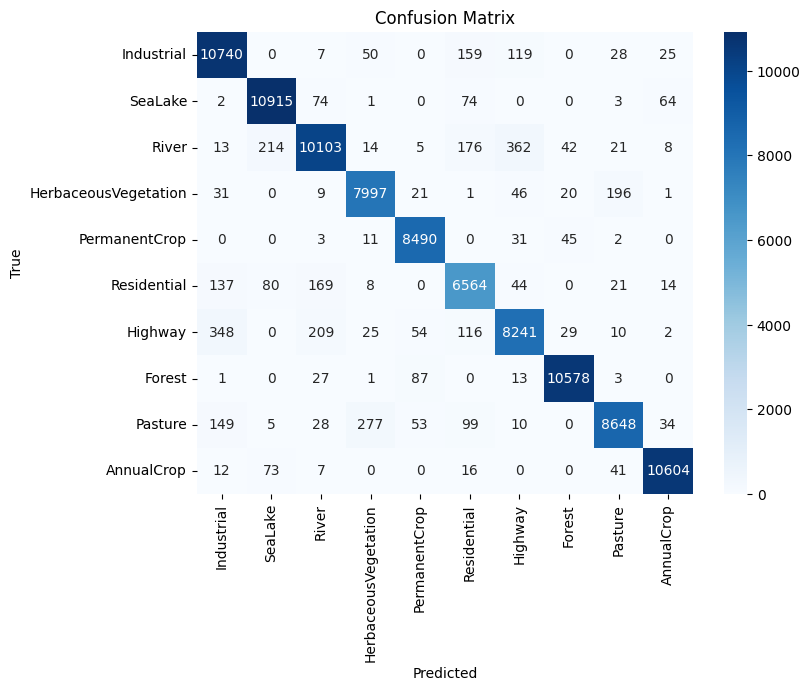

In [ ]:
import seaborn as sns
confusion_matrix = np.zeros((10, 10))
for i in range(len(true_labels)):
  true_idx = true_labels[i]
  pred_idx = pred_labels[i]
  confusion_matrix[true_idx][pred_idx] += 1

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix, annot=True, cmap='Blues', fmt='g', xticklabels=['Industrial', 'SeaLake', 'River', 'HerbaceousVegetation', 'PermanentCrop', 'Residential', 'Highway', 'Forest', 'Pasture', 'AnnualCrop'], yticklabels=['Industrial', 'SeaLake', 'River', 'HerbaceousVegetation', 'PermanentCrop', 'Residential', 'Highway', 'Forest', 'Pasture', 'AnnualCrop'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.savefig('confusion_matrix.pdf')
plt.show()

# Save the trained model
torch.save(model.state_dict(), 'model.pth')


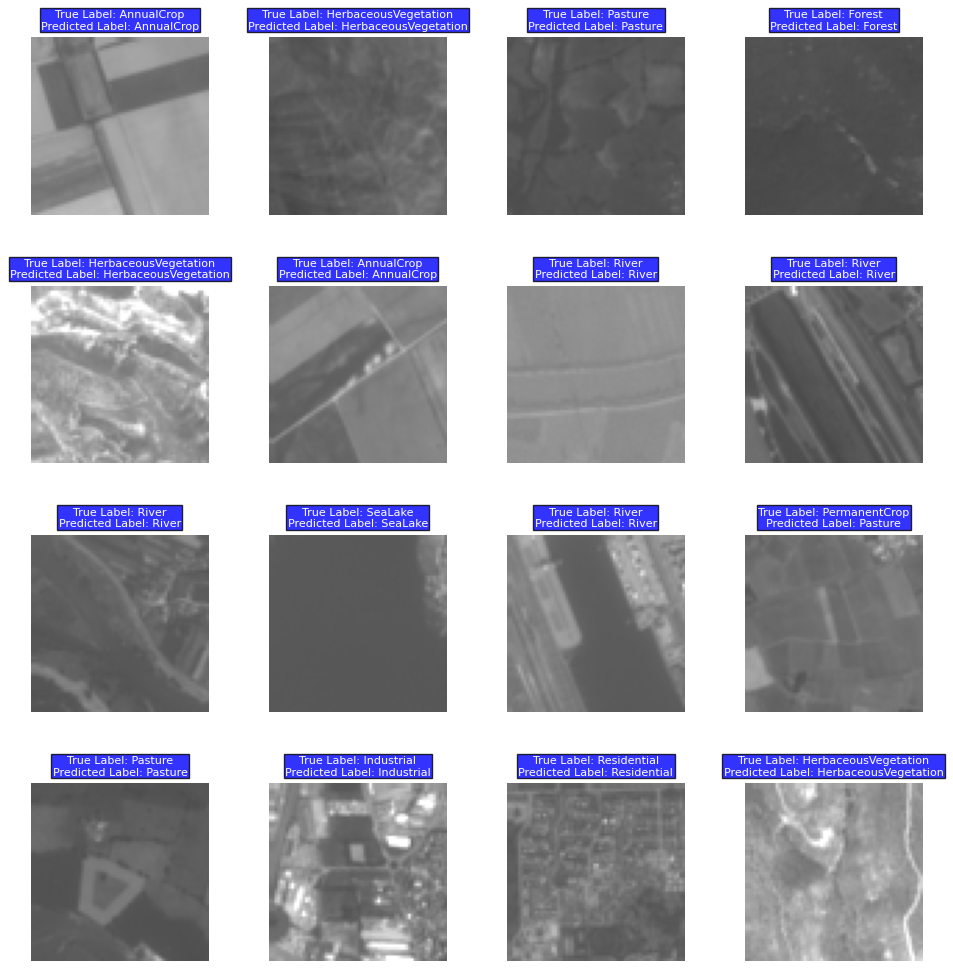

In [ ]:
# Choose 16 random samples from the test set
samples = np.random.choice(len(test_set), size=16, replace=False)

# Create a 4x4 grid of subplots to display the images
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(12, 12))

# Evaluate the model on the chosen samples and display the images with true and predicted labels
for i, ax in enumerate(axes.flat):
    image, true_label = test_set[samples[i]]
    model.eval()
    with torch.no_grad():
        output = model(image.unsqueeze(0).cuda())
    _, predicted_label = torch.max(output.data, 1)

    # Convert the image to grayscale
    gray_img = torch.mean(image, dim=0, keepdim=True)
    plot_img = gray_img.repeat(3, 1, 1)

    # Increase the brightness of the image by a factor of 4
    plot_img = np.clip(plot_img.cpu().numpy() * 4, 0, 1)

    ax.imshow(plot_img.transpose(1, 2, 0))
    ax.set_title('True Label: {}\nPredicted Label: {}'.format(classes[true_label], classes[predicted_label]),
                 fontsize=8, color='white', bbox=dict(facecolor='blue', alpha=0.8, pad=1))
    ax.axis('off')

plt.subplots_adjust(wspace=0.1, hspace=0.4)
plt.show()


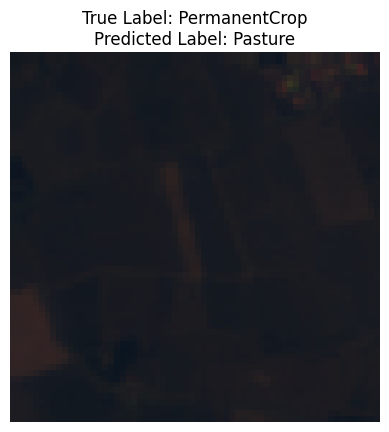

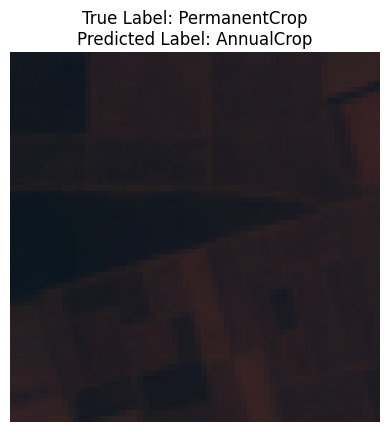

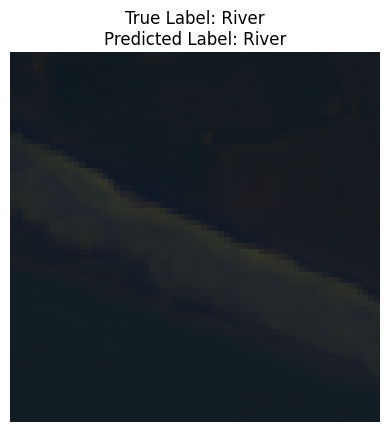

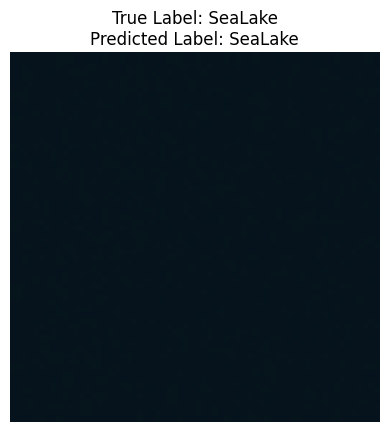

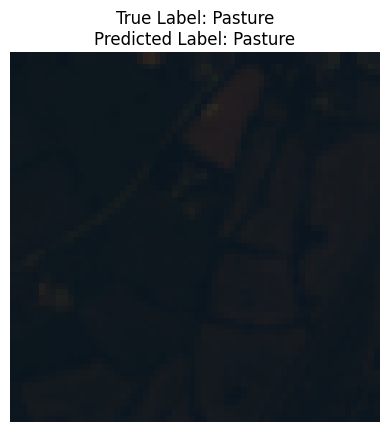

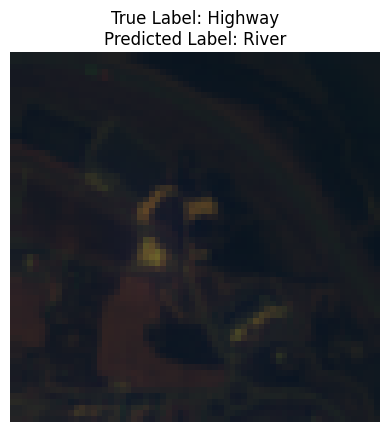

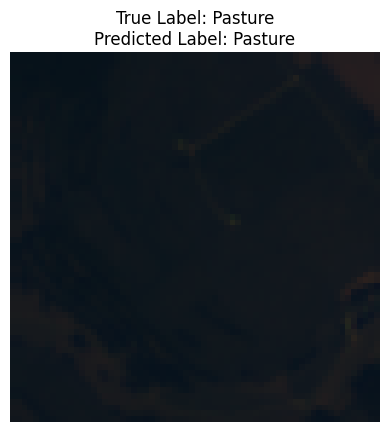

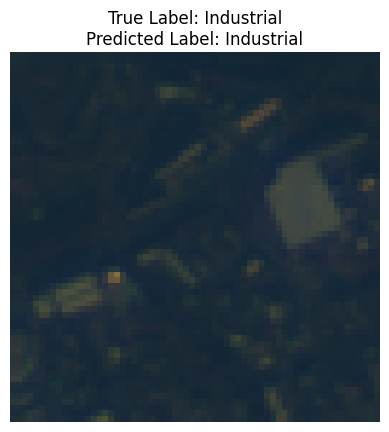

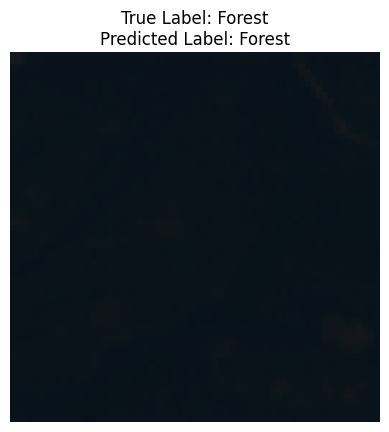

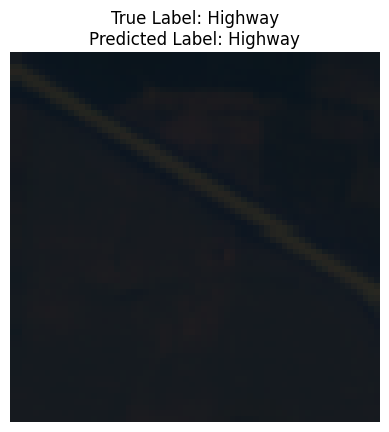

In [ ]:
# Choose 5 random samples from the test set
samples = np.random.choice(len(test_set), size=10, replace=False)

# Evaluate the model on the chosen samples and display the images with true and predicted labels
for i in samples:
    image, true_label = test_set[i]
    model.eval()
    with torch.no_grad():
        output = model(image.unsqueeze(0).cuda())
    _, predicted_label = torch.max(output.data, 1)
    plt.imshow(image.permute(1, 2, 0).cpu())
    plt.title('True Label: {}\nPredicted Label: {}'.format(classes[true_label], classes[predicted_label]))
    plt.axis('off')
    plt.show()


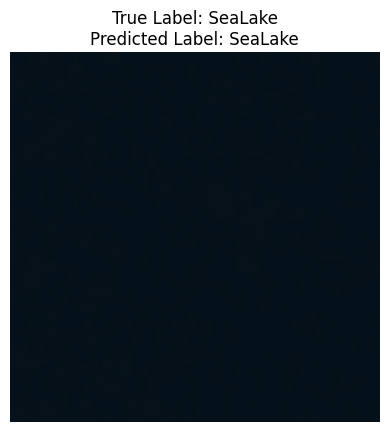

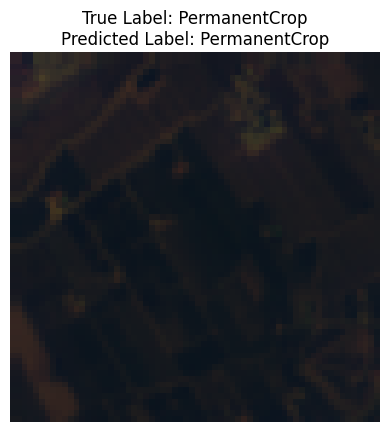

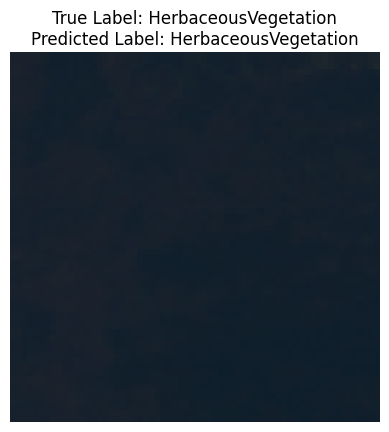

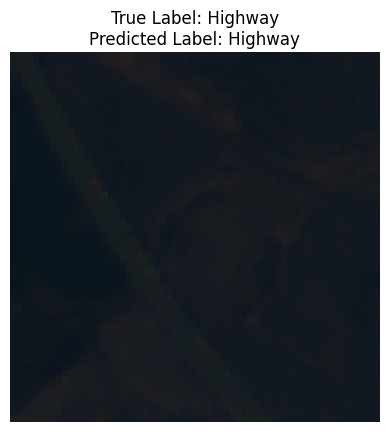

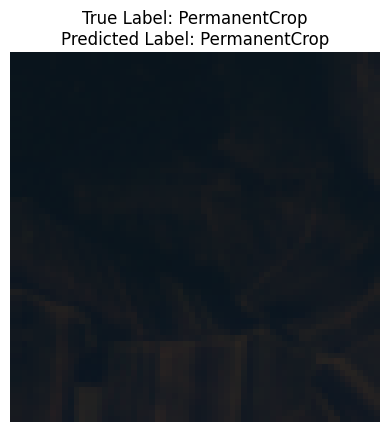

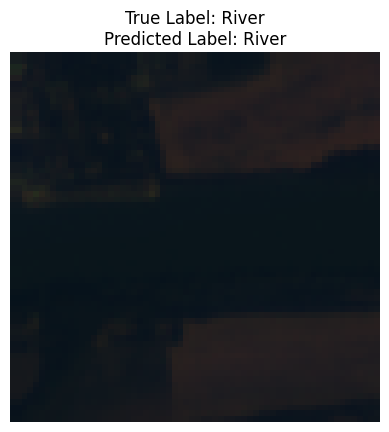

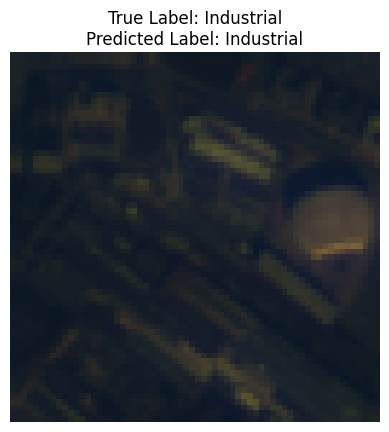

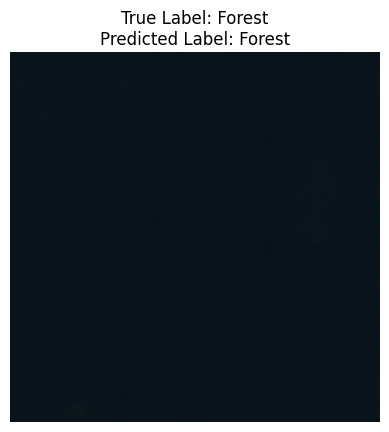

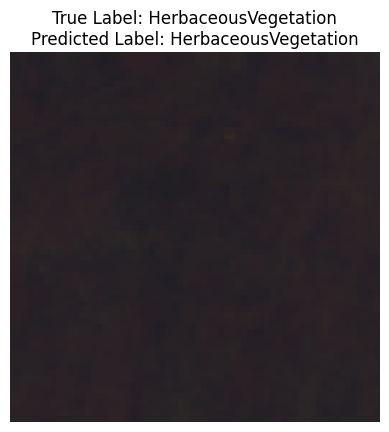

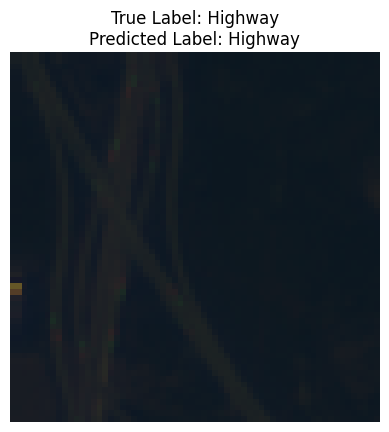

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

# Choose 5 random samples from the test set
samples = np.random.choice(len(test_set), size=10, replace=False)

# Evaluate the model on the chosen samples and display the images with true and predicted labels
with PdfPages('sample_predictions.pdf') as pdf:
    for i in samples:
        image, true_label = test_set[i]
        model.eval()
        with torch.no_grad():
            output = model(image.unsqueeze(0).cuda())
        _, predicted_label = torch.max(output.data, 1)
        plt.imshow(image.permute(1, 2, 0).cpu())
        plt.title('True Label: {}\nPredicted Label: {}'.format(classes[true_label], classes[predicted_label]))
        plt.axis('off')
        pdf.savefig()
        plt.show()


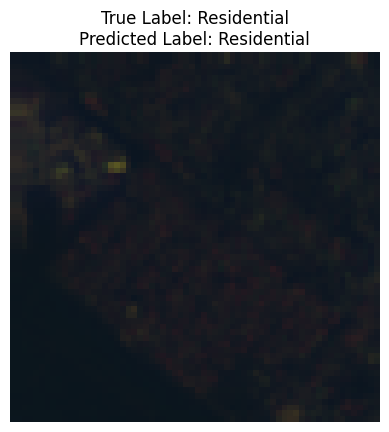

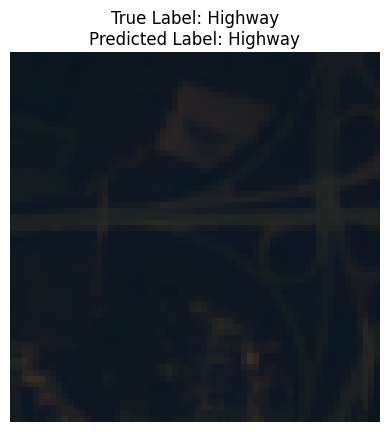

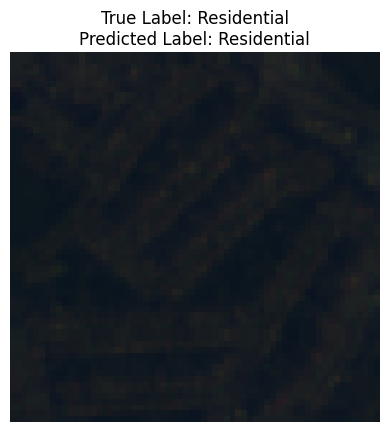

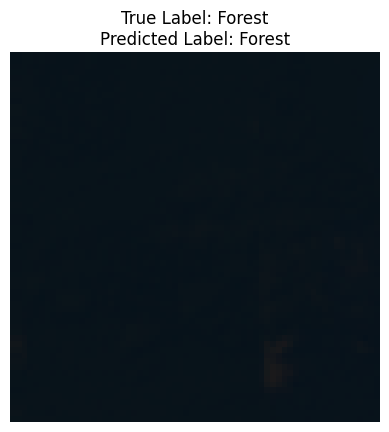

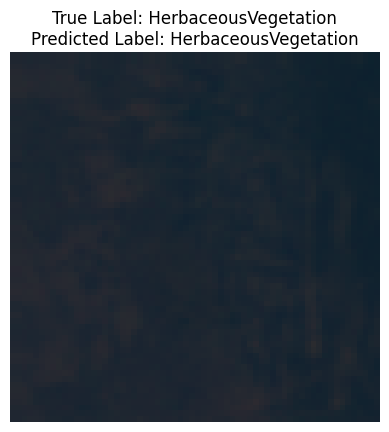

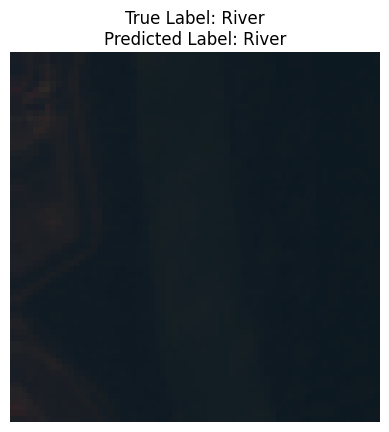

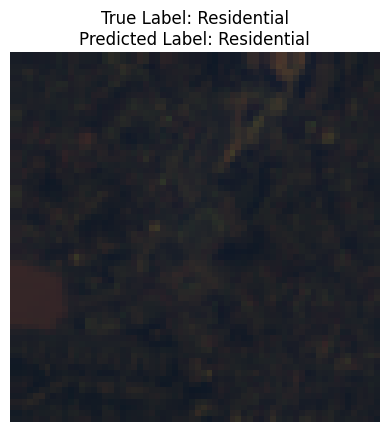

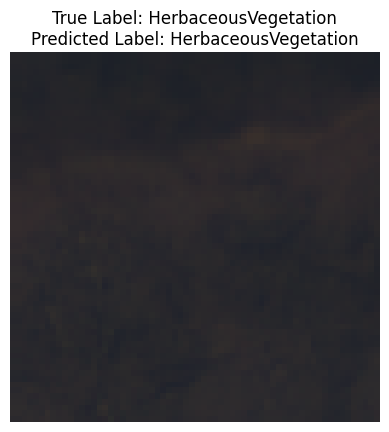

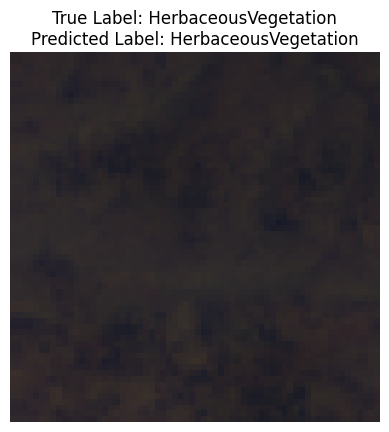

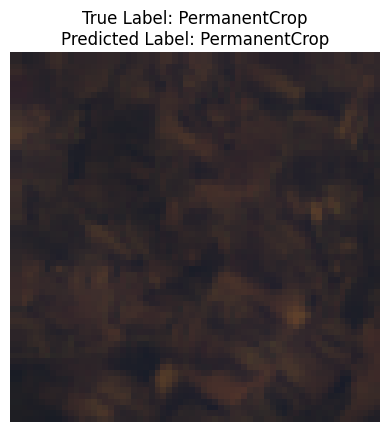

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

# Choose 5 random samples from the test set
samples = np.random.choice(len(test_set), size=10, replace=False)

# Evaluate the model on the chosen samples and display the images with true and predicted labels
with PdfPages('sample_predictions.pdf') as pdf:
    for i in samples:
        image, true_label = test_set[i]
        model.eval()
        with torch.no_grad():
            output = model(image.unsqueeze(0).cuda())
        _, predicted_label = torch.max(output.data, 1)
        plt.imshow(image.permute(1, 2, 0).cpu())
        plt.title('True Label: {}\nPredicted Label: {}'.format(classes[true_label], classes[predicted_label]))
        plt.axis('off')
        pdf.savefig()
        plt.show()


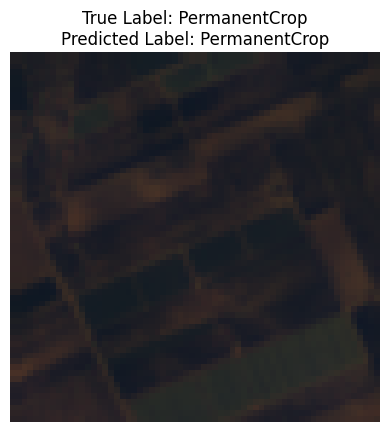

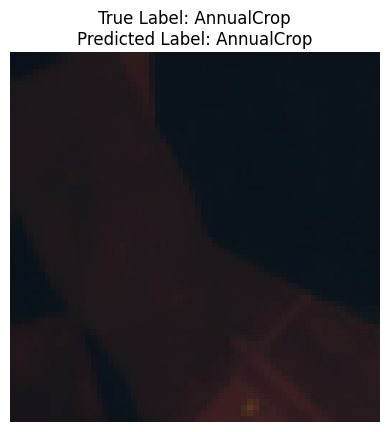

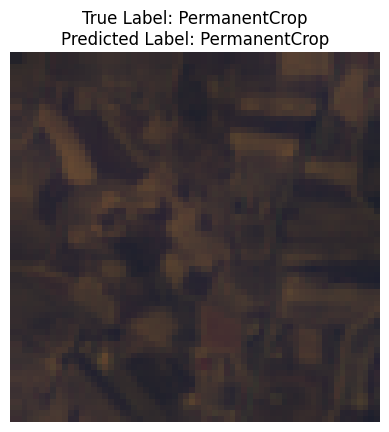

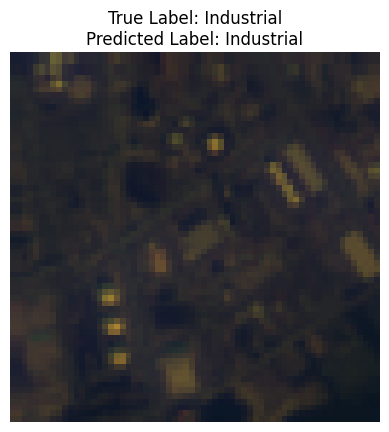

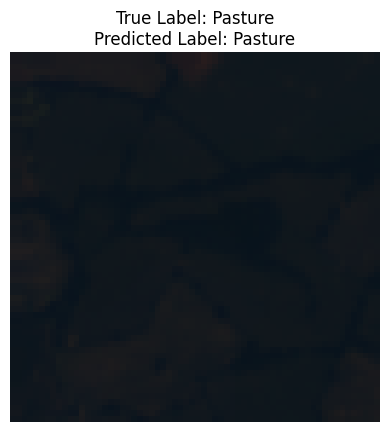

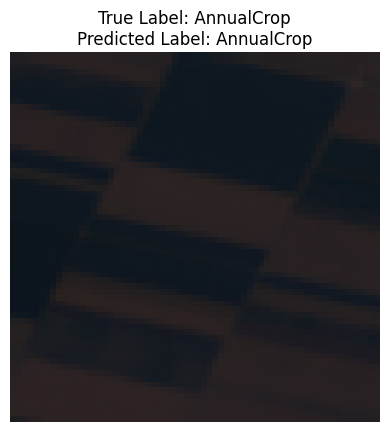

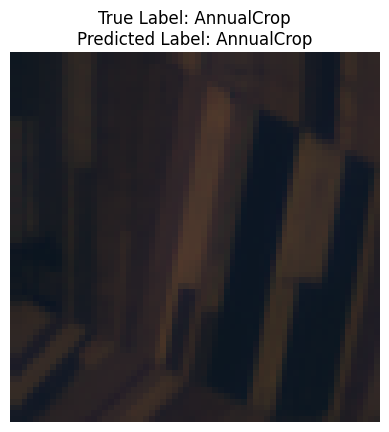

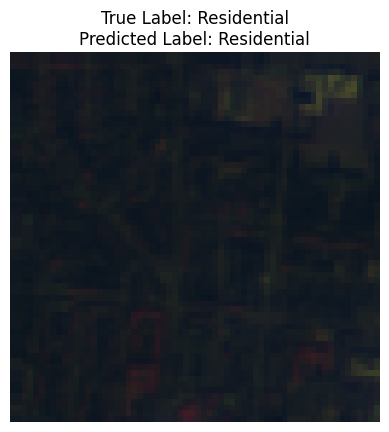

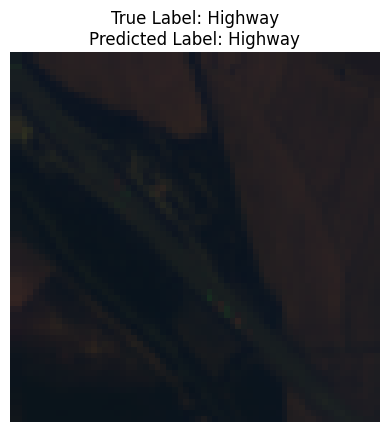

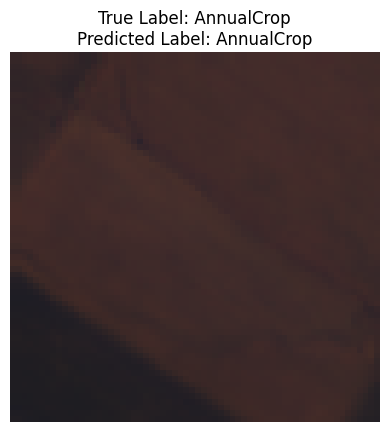

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

# Choose 5 random samples from the test set
samples = np.random.choice(len(test_set), size=10, replace=False)

# Evaluate the model on the chosen samples and display the images with true and predicted labels
with PdfPages('sample_predictions.pdf') as pdf:
    for i in samples:
        image, true_label = test_set[i]
        model.eval()
        with torch.no_grad():
            output = model(image.unsqueeze(0).cuda())
        _, predicted_label = torch.max(output.data, 1)
        plt.imshow(image.permute(1, 2, 0).cpu())
        plt.title('True Label: {}\nPredicted Label: {}'.format(classes[true_label], classes[predicted_label]))
        plt.axis('off')
        pdf.savefig()
        plt.show()


In [ ]:
import random
import torchvision.transforms.functional as F

# Saving the model
torch.save(model.state_dict(), 'model.pth')

# Evaluate on 5 random images from the test set
model.eval()
with torch.no_grad():
    for i in range(5):
        # Get a random sample from the test set
        idx = random.randint(0, len(test_set) - 1)
        inputs, label = test_set[idx]
        inputs = inputs.unsqueeze(0).cuda()
        label = label.numpy()

        # Predict the class of the sample
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        pred = preds.cpu().numpy()[0]

        # Show the sample in RGB format with its true and predicted labels
        img = F.to_pil_image(inputs.squeeze().cpu())
        img.save(f'image_{i}_true_{label}_pred_{pred}.tif')